# Data Visualization Lab Mid Project
# Name:Muhammad Sheheryar Khan
# Roll#: SP24-BDS-034
**Course:** DSC 327, BDS 6, COMSATS University Islamabad
**Dataset:** World Bank World Development Indicators (WDI), CC BY 4.0

# Part 1: Getting Started with the Data Visualization Workflow
## 1. Setup
Import libraries and create the project folders.

In [1]:
# Libraries for data handling and charts
import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt
import os

for folder in ["data/raw", "data/clean", "figures", "dashboard"]:
    os.makedirs(folder, exist_ok=True)

SOURCE = "Source: World Bank WDI (CC BY 4.0)"

In [2]:
import plotly.graph_objects as go

# Every time a chart is saved as HTML, also save a PNG next to it
_original_write_html = go.Figure.write_html

def write_html_and_png(self, file, *args, **kwargs):
    _original_write_html(self, file, *args, **kwargs)
    if isinstance(file, str) and file.endswith(".html"):
        self.write_image(file.replace(".html", ".png"), width=1100, height=650)

go.Figure.write_html = write_html_and_png

## 2. Load the data
The WDI file has thousands of indicators with one column per year (wide format). I keep only the 5 I need.

In [3]:
wide = pd.read_csv("data/raw/WDICSV.csv")

# Indicator code -> readable column name
codes = {
    "SP.DYN.LE00.IN": "life_expectancy",
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "EN.GHG.CO2.PC.CE.AR5": "co2_per_capita",
    "IT.NET.USER.ZS": "internet_users_pct",
    "SP.POP.TOTL": "population",
}

# Keep only rows for our 5 indicators
wide = wide[wide["Indicator Code"].isin(codes.keys())]
print(wide.shape)
wide["Indicator Code"].value_counts()

(1330, 70)


Indicator Code
EN.GHG.CO2.PC.CE.AR5    266
NY.GDP.PCAP.CD          266
IT.NET.USER.ZS          266
SP.DYN.LE00.IN          266
SP.POP.TOTL             266
Name: count, dtype: int64

## 3. Reshape wide to long
Charts need one row per country per year. I melt the year columns into rows, then pivot so each indicator becomes its own column.

In [4]:
# Years we will analyse
years = [str(y) for y in range(1990, 2023)]

# Melt: turn the year columns into rows
long = wide.melt(
    id_vars=["Country Name", "Country Code", "Indicator Code"],
    value_vars=years,
    var_name="year",
    value_name="value",
)
long["year"] = long["year"].astype(int)
long["indicator"] = long["Indicator Code"].map(codes)

# Pivot: one column per indicator
df = long.pivot_table(
    index=["Country Code", "Country Name", "year"],
    columns="indicator",
    values="value",
).reset_index()

# Rename to simple column names
df = df.rename(columns={"Country Code": "iso3", "Country Name": "country"})
print(df.shape)
df.head()

(8745, 8)


indicator,iso3,country,year,co2_per_capita,gdp_per_capita,internet_users_pct,life_expectancy,population
0,ABW,Aruba,1990,3.203034,12187.536361,0.0,72.546,62753.0
1,ABW,Aruba,1991,3.435717,13233.990517,NaN,72.592,65896.0
2,ABW,Aruba,1992,3.634519,13892.605143,NaN,72.717,69005.0
3,ABW,Aruba,1993,3.414535,14700.959808,NaN,72.777,73685.0
4,ABW,Aruba,1994,3.683227,16055.287787,NaN,72.796,77595.0


## 4. Add region and remove aggregates
WDI mixes real countries with groups such as "World" or "Low income". Those would double count. In the country file, groups have no region, so rows without a region are dropped.

In [5]:
# Country metadata file contains the World Bank region for each country
countries = pd.read_csv("data/raw/WDICountry.csv")
region_map = countries.set_index("Country Code")["Region"]

# Attach region; aggregates get NaN and are removed
df["region"] = df["iso3"].map(region_map)
df = df.dropna(subset=["region"])

# Save the combined raw table
df.to_csv("data/raw/wdi_raw.csv", index=False)
print(df.shape, df["country"].nunique(), "countries")
df.head()

(7161, 9) 217 countries


indicator,iso3,country,year,co2_per_capita,gdp_per_capita,internet_users_pct,life_expectancy,population,region
0,ABW,Aruba,1990,3.203034,12187.536361,0.0,72.546,62753.0,Latin America & Caribbean
1,ABW,Aruba,1991,3.435717,13233.990517,NaN,72.592,65896.0,Latin America & Caribbean
2,ABW,Aruba,1992,3.634519,13892.605143,NaN,72.717,69005.0,Latin America & Caribbean
3,ABW,Aruba,1993,3.414535,14700.959808,NaN,72.777,73685.0,Latin America & Caribbean
4,ABW,Aruba,1994,3.683227,16055.287787,NaN,72.796,77595.0,Latin America & Caribbean


## 5. Data dictionary
Each column with its meaning, data type (nominal, ordinal, interval, ratio), unit, role, and missing value count.

**Relationship table:** UN DESA International Migrant Stock (origin country, destination country, number of migrants), used in Part 8.

In [6]:
dictionary = pd.DataFrame({
    "column": ["iso3", "country", "year", "life_expectancy", "gdp_per_capita",
               "co2_per_capita", "internet_users_pct", "population", "region"],
    "meaning": ["Country code", "Country name", "Year", "Life expectancy at birth",
                "GDP per person", "CO2 emissions per person",
                "Share of people using internet", "Total population", "World Bank region"],
    "data_type": ["nominal", "nominal", "interval", "ratio", "ratio",
                  "ratio", "ratio", "ratio", "nominal"],
    "unit": ["code", "text", "year", "years", "US$", "tonnes CO2e",
             "% of population", "people", "text"],
    "role": ["place field", "place field", "time field", "outcome measure", "numeric",
             "numeric", "numeric", "numeric", "category"],
})

# Count missing values per column
dictionary["missing_values"] = [df[c].isna().sum() for c in dictionary["column"]]
dictionary.to_csv("data/clean/data_dictionary.csv", index=False)
dictionary

,column,meaning,data_type,unit,role,missing_values
0,iso3,Country code,nominal,code,place field,0
1,country,Country name,nominal,text,place field,0
2,year,Year,interval,year,time field,0
3,life_expectancy,Life expectancy at birth,ratio,years,outcome measure,0
4,gdp_per_capita,GDP per person,ratio,US$,numeric,350
5,co2_per_capita,CO2 emissions per person,ratio,tonnes CO2e,numeric,462
6,internet_users_pct,Share of people using internet,ratio,% of population,numeric,1310
7,population,Total population,ratio,people,numeric,0
8,region,World Bank region,nominal,text,category,0


## 6. Cleaning log
Every cleaning decision is recorded in a list and saved to `cleaning_log.md`.

In [7]:
log = []

# Decision 1: duplicate country-year rows would double count
before = len(df)
df = df.drop_duplicates(subset=["iso3", "year"])
log.append(f"Removed {before - len(df)} duplicate country-year rows.")

# Decision 2: standardise labels
df["country"] = df["country"].str.strip()
df["region"] = df["region"].str.strip()
log.append("Stripped extra spaces from country and region names.")

# Decision 3: core variables cannot be guessed, so drop those rows
before = len(df)
df = df.dropna(subset=["life_expectancy", "gdp_per_capita", "population"])
log.append(f"Dropped {before - len(df)} rows missing life expectancy, GDP or population.")

# Decision 4: other gaps stay missing (zero would be false)
log.append("CO2 and internet gaps left as NaN, not filled with 0.")

# Decision 5: GDP is very skewed, so add a log version
df["gdp_log10"] = np.log10(df["gdp_per_capita"])
log.append("Added gdp_log10 because GDP is heavily skewed.")

# Save the clean table and the log file
df.to_csv("data/clean/wdi_clean.csv", index=False)
with open("cleaning_log.md", "w") as f:
    f.write("# Cleaning log\n")
    for i, line in enumerate(log, 1):
        f.write(f"{i}. {line}\n")

for line in log:
    print("-", line)
print(df.shape)

- Removed 0 duplicate country-year rows.
- Stripped extra spaces from country and region names.
- Dropped 350 rows missing life expectancy, GDP or population.
- CO2 and internet gaps left as NaN, not filled with 0.
- Added gdp_log10 because GDP is heavily skewed.
(6811, 10)


In [8]:
# Decision 6: CAR life expectancy swings by 20+ years between years (18.8 in 2022, 31.5 in 2019),
# which is not plausible, so the whole country is removed rather than one year
df = df[df["country"] != "Central African Republic"]
log.append("Removed Central African Republic: its life expectancy series jumps implausibly between years (e.g. 31.5 in 2019, 50.6 in 2020, 18.8 in 2022), likely a source error.")

# Save the clean table and rewrite the log file
df.to_csv("data/clean/wdi_clean.csv", index=False)
with open("cleaning_log.md", "w") as f:
    f.write("# Cleaning log\n")
    for i, line in enumerate(log, 1):
        f.write(f"{i}. {line}\n")

print(log[-1])
print(df.shape)

Removed Central African Republic: its life expectancy series jumps implausibly between years (e.g. 31.5 in 2019, 50.6 in 2020, 18.8 in 2022), likely a source error.
(6778, 10)


## 7. Choose the latest year
Later parts use "the latest year". I check which recent year still has data for at least 150 countries in the two sparsest columns.

In [9]:
# Number of countries with data per year for the two sparsest columns
coverage = df.groupby("year")[["co2_per_capita", "internet_users_pct"]].count()
coverage.tail(8)

indicator,co2_per_capita,internet_users_pct
year,,
2015,198,199
2016,198,198
2017,198,196
2018,198,179
2019,197,185
2020,197,183
2021,196,179
2022,196,180


In [10]:
LATEST = 2022   # newest year where both co2 and internet cover 179+ countries
latest = df[df["year"] == LATEST]
print(len(latest), "countries in", LATEST)

208 countries in 2022


## 8. Ask: three analytic questions
1. **Time:** For a ministry of health, how does life expectancy vary over time by region?
2. **Place:** For a news readership, how does life expectancy vary by country wealth in the latest year?
3. **Relationship:** For a migration analyst, how do migrant flows vary by origin and destination region?

I build a chart for Question 2. Audience: news readership.

## 9. Encode and first draft
GDP per capita (ratio) goes on the x position and life expectancy (ratio) on the y position. Position on a common scale is the most accurate channel. This first draft is deliberately rough so I can critique it.

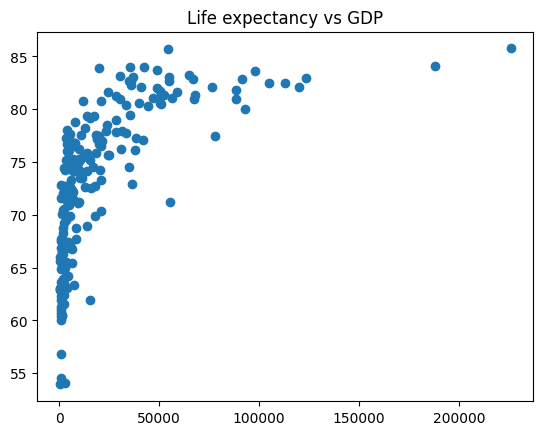

In [11]:
# Rough first chart: linear scale, no colour, no finding in the title
plt.scatter(latest["gdp_per_capita"], latest["life_expectancy"])
plt.title("Life expectancy vs GDP")
plt.savefig("figures/p1_static_draft.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Evaluate: critique of the draft
1. The x axis is linear, so most countries are squashed on the left. I will use a log scale.
2. There is no colour by region, so groups are invisible.
3. The title states no finding, and there are no axis units or source note.

## 11. Interactive upgrade (Plotly Express)
Rebuilds the same chart with a log x axis, colour by region, a finding title, units, a source note, and hover tooltips.

In [12]:
fig = px.scatter(
    latest,
    x="gdp_per_capita",
    y="life_expectancy",
    color="region",              # fixes critique 2: groups visible
    log_x=True,                  # fixes critique 1: log scale spreads countries out
    hover_name="country",        # tooltip shows the country name
    hover_data={"population": ":,", "gdp_per_capita": ":,.0f", "life_expectancy": ":.1f"},
    labels={"gdp_per_capita": "GDP per capita (US$, log scale)",
            "life_expectancy": "Life expectancy (years)"},
    title=f"Richer countries live longer, but gains flatten at high income ({LATEST})",  # fixes critique 3
)

# Source note under the chart
fig.add_annotation(text=SOURCE, xref="paper", yref="paper", x=0, y=-0.2, showarrow=False)

# Save as interactive HTML and show
fig.write_html("figures/p1_interactive.html")
fig.show()

## 12. Communicate
**What the interactive version reveals:** hovering shows the country name and exact values, and the legend lets the reader hide regions. The static version hid all of that.

**Takeaway:** Life expectancy rises steeply with income at first, then levels off.

## Part 1 reflection
Preparing the data took longest, which shows most visualization effort goes into data work, not drawing.

# Part 2: Visual Perception, Cognition, and Real-World Applications

## 1. Perception experiment
**Ask:** Which encoding lets people judge the ratio between the largest and smallest value most accurately?
**Audience:** classmates (general readers).
I take five values of life expectancy and show them as a bar chart, a pie chart, a bubble-size chart and a colour-intensity strip. Classmates estimate the ratio of the largest to the smallest value in each.

In [13]:
# Sort countries by life expectancy, then pick five evenly spread from lowest to highest
ranked = latest.sort_values("life_expectancy").reset_index(drop=True)
positions = np.linspace(0, len(ranked) - 1, 5).round().astype(int)

five = ranked.loc[positions, ["country", "life_expectancy"]].reset_index(drop=True)
five["label"] = ["A", "B", "C", "D", "E"]   # classmates see letters, not country names

# Answer key: true ratio of largest to smallest (keep this hidden from classmates)
true_ratio = five["life_expectancy"].max() / five["life_expectancy"].min()
print(five)
print("True ratio:", round(true_ratio, 2))

indicator                   country  life_expectancy label
0                Somalia, Fed. Rep.           53.931     A
1                           Senegal           67.788     B
2                        Bangladesh           74.265     C
3          Northern Mariana Islands           78.531     D
4                            Monaco           85.746     E
True ratio: 1.59


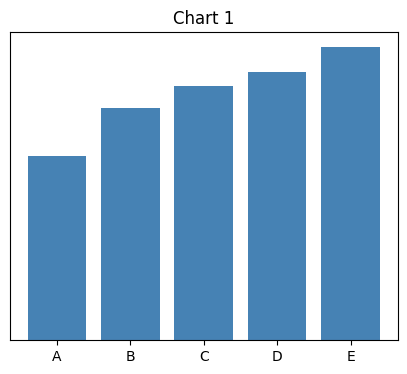

In [14]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(five["label"], five["life_expectancy"], color="steelblue")
ax.set_yticks([])                       # hide numbers so people judge by length only
ax.set_title("Chart 1")
plt.savefig("figures/p2_bar.png", dpi=150, bbox_inches="tight")
plt.show()

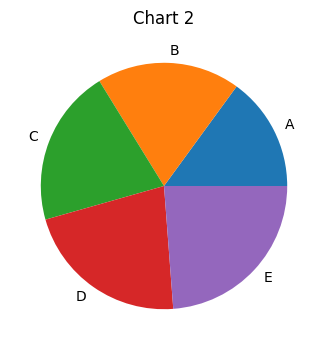

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.pie(five["life_expectancy"], labels=five["label"])
ax.set_title("Chart 2")
plt.savefig("figures/p2_pie.png", dpi=150, bbox_inches="tight")
plt.show()

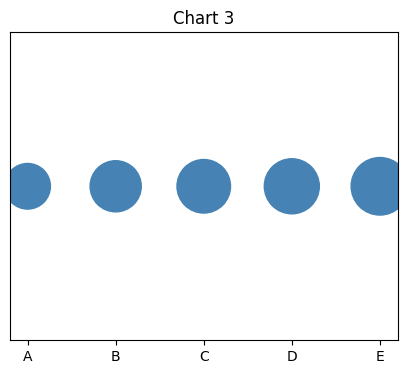

In [16]:
fig, ax = plt.subplots(figsize=(5, 4))
# s is the bubble AREA, so it is proportional to the value
ax.scatter(range(5), [0] * 5, s=five["life_expectancy"] * 20, color="steelblue")
ax.set_xticks(range(5))
ax.set_xticklabels(five["label"])
ax.set_yticks([])
ax.set_title("Chart 3")
plt.savefig("figures/p2_bubble.png", dpi=150, bbox_inches="tight")
plt.show()

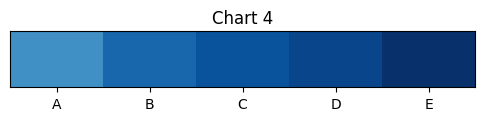

In [17]:
fig, ax = plt.subplots(figsize=(6, 2))
# Darker blue = bigger value; scale starts at 0 so it is honest
ax.imshow([five["life_expectancy"].values], cmap="Blues", vmin=0, vmax=five["life_expectancy"].max(), aspect=0.6)
ax.set_xticks(range(5))
ax.set_xticklabels(five["label"])
ax.set_yticks([])
ax.set_title("Chart 4")
plt.savefig("figures/p2_strip.png", dpi=150, bbox_inches="tight")
plt.show()

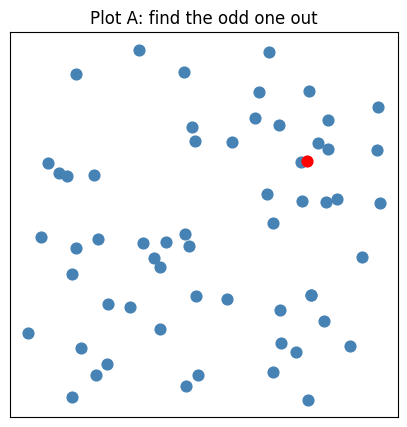

In [18]:
rng = np.random.default_rng(42)          # fixed seed so the plot is reproducible
x = rng.random(60)
y = rng.random(60)

# Plot A: one red target among 59 blue points (hue only)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(x[1:], y[1:], color="steelblue", s=60)
ax.scatter(x[0], y[0], color="red", s=60)
ax.set_title("Plot A: find the odd one out")
ax.set_xticks([]); ax.set_yticks([])
plt.savefig("figures/p2_preattentive_hue.png", dpi=150, bbox_inches="tight")
plt.show()

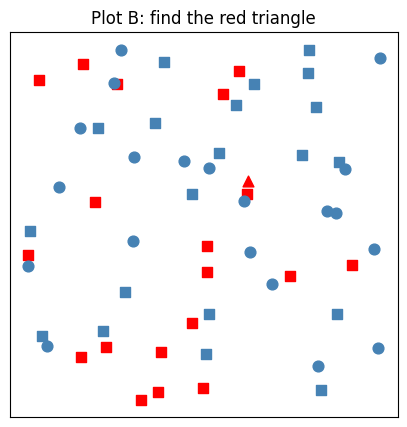

In [19]:
rng = np.random.default_rng(7)           # different seed, new layout
x = rng.random(60)
y = rng.random(60)

fig, ax = plt.subplots(figsize=(5, 5))

# 59 distractors: a mix of blue circles, red squares, and blue squares
for i in range(1, 60):
    if i % 3 == 0:
        ax.scatter(x[i], y[i], color="red", marker="s", s=60)        # red square
    elif i % 3 == 1:
        ax.scatter(x[i], y[i], color="steelblue", marker="o", s=60)  # blue circle
    else:
        ax.scatter(x[i], y[i], color="steelblue", marker="s", s=60)  # blue square

# One target: red triangle (only point with red AND triangle)
ax.scatter(x[0], y[0], color="red", marker="^", s=60)

ax.set_title("Plot B: find the red triangle")
ax.set_xticks([]); ax.set_yticks([])
plt.savefig("figures/p2_preattentive_conjunction.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Cognitive load audit
**Ask:** Which elements of a chart carry no information, and what happens when I remove them?
**Before:** a cluttered chart with heavy grid, border, 3D-style marker edges, redundant legend and background. **After:** only the data, labelled axes, and a finding title.

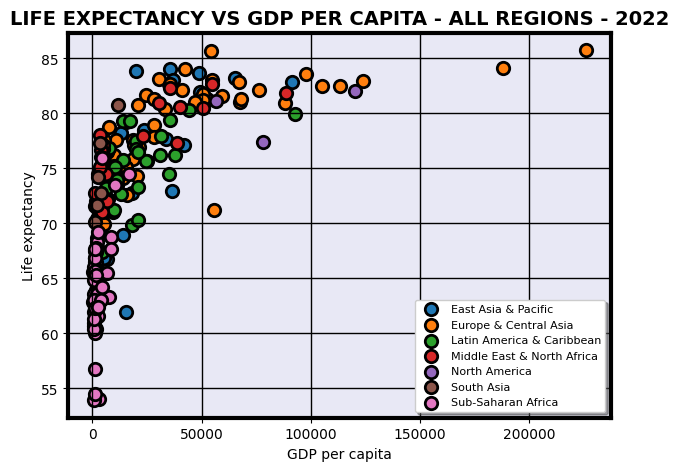

In [20]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor("#e8e8f5")                      # coloured background (no information)
ax.grid(True, color="black", linewidth=1)        # heavy grid (competes with data)

# Same data as Part 1, but every region gets its own marker AND colour, with thick edges
for region, g in latest.groupby("region"):
    ax.scatter(g["gdp_per_capita"], g["life_expectancy"],
               s=80, edgecolor="black", linewidth=2, label=region)

ax.legend(loc="lower right", frameon=True, shadow=True, fontsize=8)
ax.set_title("LIFE EXPECTANCY VS GDP PER CAPITA - ALL REGIONS - 2022", fontsize=14, fontweight="bold")
ax.set_xlabel("GDP per capita"); ax.set_ylabel("Life expectancy")
for spine in ax.spines.values():
    spine.set_linewidth(3)                       # thick border (no information)
plt.savefig("figures/p2_clutter_before.png", dpi=150, bbox_inches="tight")
plt.show()

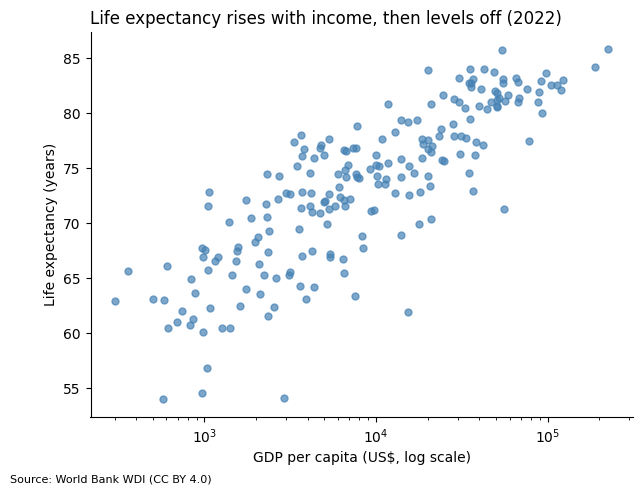

In [21]:
fig, ax = plt.subplots(figsize=(7, 5))

# Single muted colour: the pattern is the message, region detail moves to tooltips later
ax.scatter(latest["gdp_per_capita"], latest["life_expectancy"],
           s=25, color="steelblue", alpha=0.7)
ax.set_xscale("log")

# Remove non-data ink: top and right borders, grid, background colour
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlabel("GDP per capita (US$, log scale)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Life expectancy rises with income, then levels off (2022)", loc="left")
fig.text(0.01, -0.02, SOURCE, fontsize=8)
plt.savefig("figures/p2_clutter_after.png", dpi=150, bbox_inches="tight")
plt.show()

**Removed:** coloured background, heavy black grid, thick borders, thick marker edges, shadowed legend, all-caps title.
**Kept:** the points, axis labels with units, a title that states the finding, and the source note.
**Why it helps:** with less non-data ink, the eye goes straight to the pattern, so less effort is spent filtering out decoration.

## 4. Real-world application brief
**Domain:** public health dashboards

During COVID-19, health ministries and news outlets published line charts of daily new cases, often with a 7-day average. Officials used these charts to decide when to tighten or relax restrictions, such as closing schools or limiting gatherings. The decision depended on one question: is the curve rising or falling?

The chart works because of **position on a common scale**, the most accurate visual channel. A reader can judge direction and steepness at a glance by following one line along a shared time axis. The 7-day average smooths daily noise, so the trend is not hidden by weekend reporting dips. Direct labels and a single highlighted line also reduce cognitive load, so the reader does not have to search a legend.

**Principle:** position on a common scale, plus preattentive attention to the one highlighted line.

## 5. Interactive Overview Plus Detail

**Ask:** How does GDP per capita relate to life expectancy across different regions?

**Overview:** Display all countries in a scatter plot.

**Filter:** Allow users to select a particular region.

**Details on demand:** Hovering over a country reveals its name, GDP per capita, life expectancy, and population.

**Why it reduces cognitive load:** Instead of displaying every detail directly on the chart, secondary information is available only when requested.

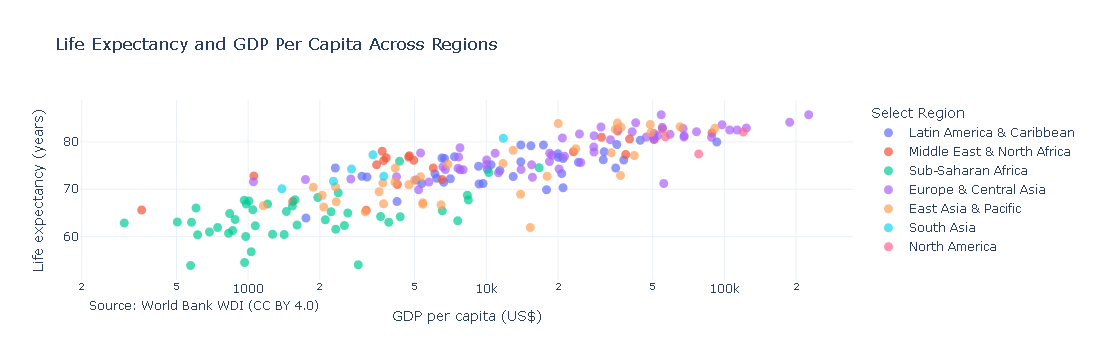

In [22]:
import plotly.express as px

regions = sorted(latest["region"].dropna().unique())

fig = px.scatter(
    latest,
    x="gdp_per_capita",
    y="life_expectancy",
    color="region",
    hover_name="country",
    hover_data={
        "gdp_per_capita": ":,.0f",
        "life_expectancy": ":.1f",
        "population": ":,.0f"
    },
    log_x=True,
    labels={
        "gdp_per_capita": "GDP per capita (US$)",
        "life_expectancy": "Life expectancy (years)",
        "region": "Region"
    },
    title="Life Expectancy and GDP Per Capita Across Regions"
)

fig.update_layout(
    template="plotly_white",
    legend_title="Select Region",
    hovermode="closest"
)

fig.update_traces(marker=dict(size=9, opacity=0.7))

fig.add_annotation(
    text=SOURCE,
    xref="paper",
    yref="paper",
    x=0,
    y=-0.2,
    showarrow=False
)

fig.write_html("figures/p2_interactive_overview.html")

fig.show()

**Evaluation:**

The interactive chart follows Shneiderman's mantra.

- Overview first: All countries are displayed together.
- Zoom and filter: Readers can zoom into the chart and select or hide regions using the legend.
- Details on demand: Hovering over a point reveals the country's exact values.

This reduces cognitive load because the chart does not display every numerical value simultaneously. Readers can explore only the information they need.

**Takeaway:** Interactive filtering and tooltips make the visualization easier to explore without overcrowding the chart.

# Part 3 — Visual Encoding and Gestalt Principles

## 1. Encoding Map

**Objective:** Assign appropriate visual channels to different dataset fields based on their data types and perceptual accuracy.

Visual encoding is the process of representing data values through visual properties such as position, length, colour, size, and shape.

| Dataset Field | Data Type | Visual Channel | Justification |
|---|---|---|---|
| Life Expectancy | Ratio | Position (Y-axis) | Position on a common scale allows accurate numerical comparison. |
| GDP per Capita | Ratio | Position (X-axis) | Position makes it easy to identify relationships between numerical variables. |
| Region | Nominal | Colour Hue | Different colours distinguish categories without implying an order. |
| Year | Interval | Position (X-axis) | Position along a continuous timeline makes changes over time easy to understand. |
| Population | Ratio | Area (Bubble Size) | Bubble area represents population magnitude, allowing comparison of relative sizes. |

### Justification

Position on a common scale is considered one of the most accurate visual channels because people can easily compare the locations of different data points.

Length is also highly accurate, while angle, area, and colour intensity are generally less accurate for precise numerical comparisons.

Colour hue is particularly useful for distinguishing nominal categories such as geographical regions.

In our dataset, position is used for GDP per capita, life expectancy, and year because these variables require accurate comparisons. Colour hue represents region because it is categorical. Area represents population because bubble charts allow multiple variables to be displayed simultaneously.

**Conclusion:** Selecting appropriate visual channels improves readability, reduces confusion, and helps readers understand patterns in the dataset.

In [23]:
# Select latest 10 countries by life expectancy
top_10 = latest.nlargest(10, "life_expectancy").sort_values("life_expectancy")

print(top_10[["country", "life_expectancy"]])

indicator               country  life_expectancy
2342                      Spain        83.134146
461                   Australia        83.200000
1253                Switzerland        83.604878
3200       Hong Kong SAR, China        83.660976
6566           French Polynesia        83.859000
3926                      Japan        83.996341
230                     Andorra        84.016000
4520              Liechtenstein        84.121951
6995                 San Marino        85.708000
4916                     Monaco        85.746000


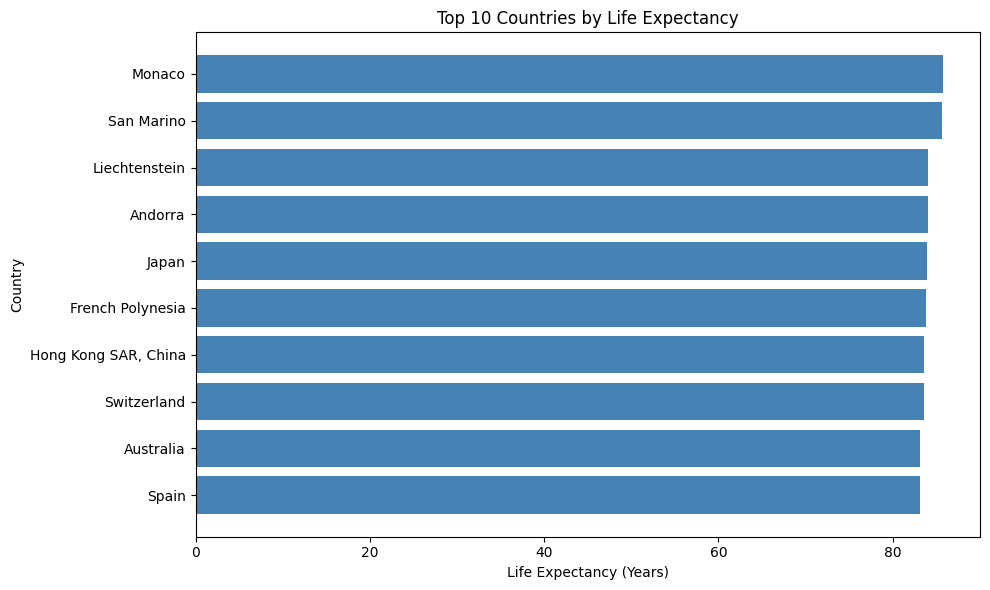

In [24]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_10["country"],
    top_10["life_expectancy"],
    color="steelblue"
)

plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Life Expectancy")

plt.tight_layout()
plt.savefig("figures/p3_bar.png", dpi=150)
plt.show()

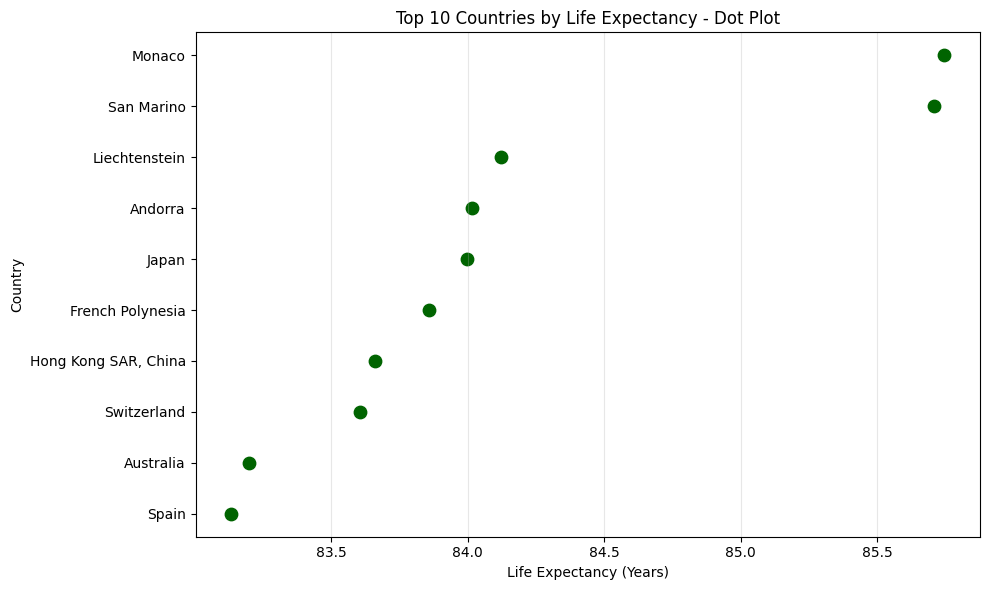

In [25]:
plt.figure(figsize=(10, 6))

plt.scatter(
    top_10["life_expectancy"],
    top_10["country"],
    color="darkgreen",
    s=80
)

plt.xlabel("Life Expectancy (Years)")
plt.ylabel("Country")
plt.title("Top 10 Countries by Life Expectancy - Dot Plot")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/p3_dot.png", dpi=150)
plt.show()

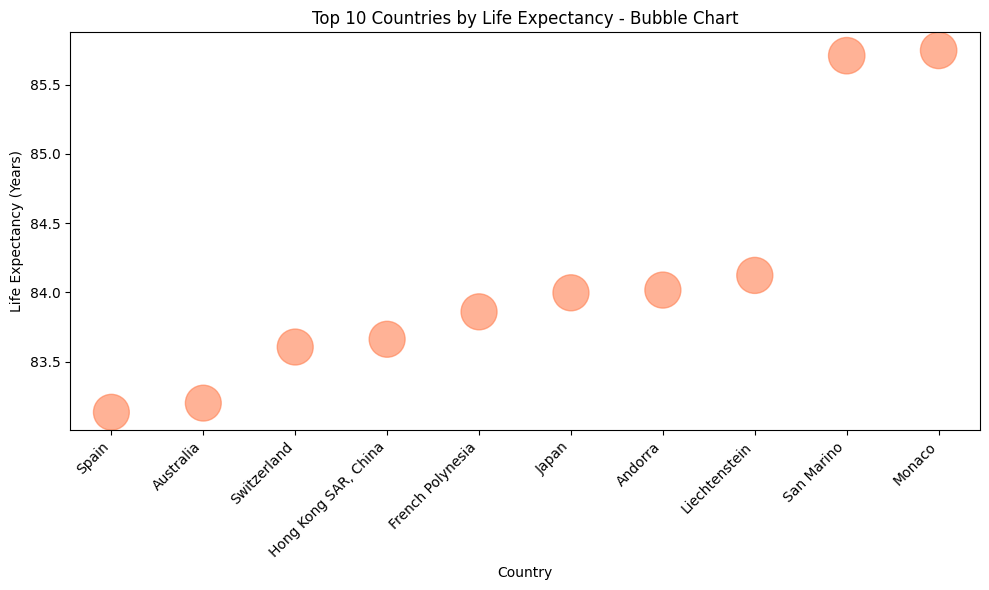

In [26]:
plt.figure(figsize=(10, 6))

plt.scatter(
    top_10["country"],
    top_10["life_expectancy"],
    s=top_10["life_expectancy"] * 8,
    alpha=0.6,
    color="coral"
)

plt.xlabel("Country")
plt.ylabel("Life Expectancy (Years)")
plt.title("Top 10 Countries by Life Expectancy - Bubble Chart")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig("figures/p3_bubble.png", dpi=150)
plt.show()

### Comparison of Three Visual Encodings

The three charts represent the same life expectancy values using different visual channels.

**Readability ranking:**

1. Dot Plot: Most readable because positions along a common scale allow accurate comparison of numerical values.
2. Bar Chart: Easy to understand because bar lengths clearly represent differences in life expectancy.
3. Bubble Chart: Least readable because comparing bubble areas is less accurate than comparing positions or lengths.

**Conclusion:** The dot plot provides the clearest numerical comparison, while the bubble chart is less suitable when precise differences between values are important.

## 3. Gestalt Redesign Using Small Multiples

**Objective:** Visualize life expectancy over time using separate panels for geographical regions.

Small multiples divide a visualization into several smaller charts, allowing readers to compare patterns across categories without overcrowding a single chart.

The following Gestalt principles are applied:

- Proximity: Related regional panels are positioned together.
- Similarity: Each region maintains a consistent colour.
- Enclosure: Each panel is separated using a light background and border.
- Continuity: All panels use aligned axes and consistent scales.
- Closure and figure-ground: Clear lines and subtle gridlines help the data stand out.

**Question:** How has life expectancy changed over time across different geographical regions?

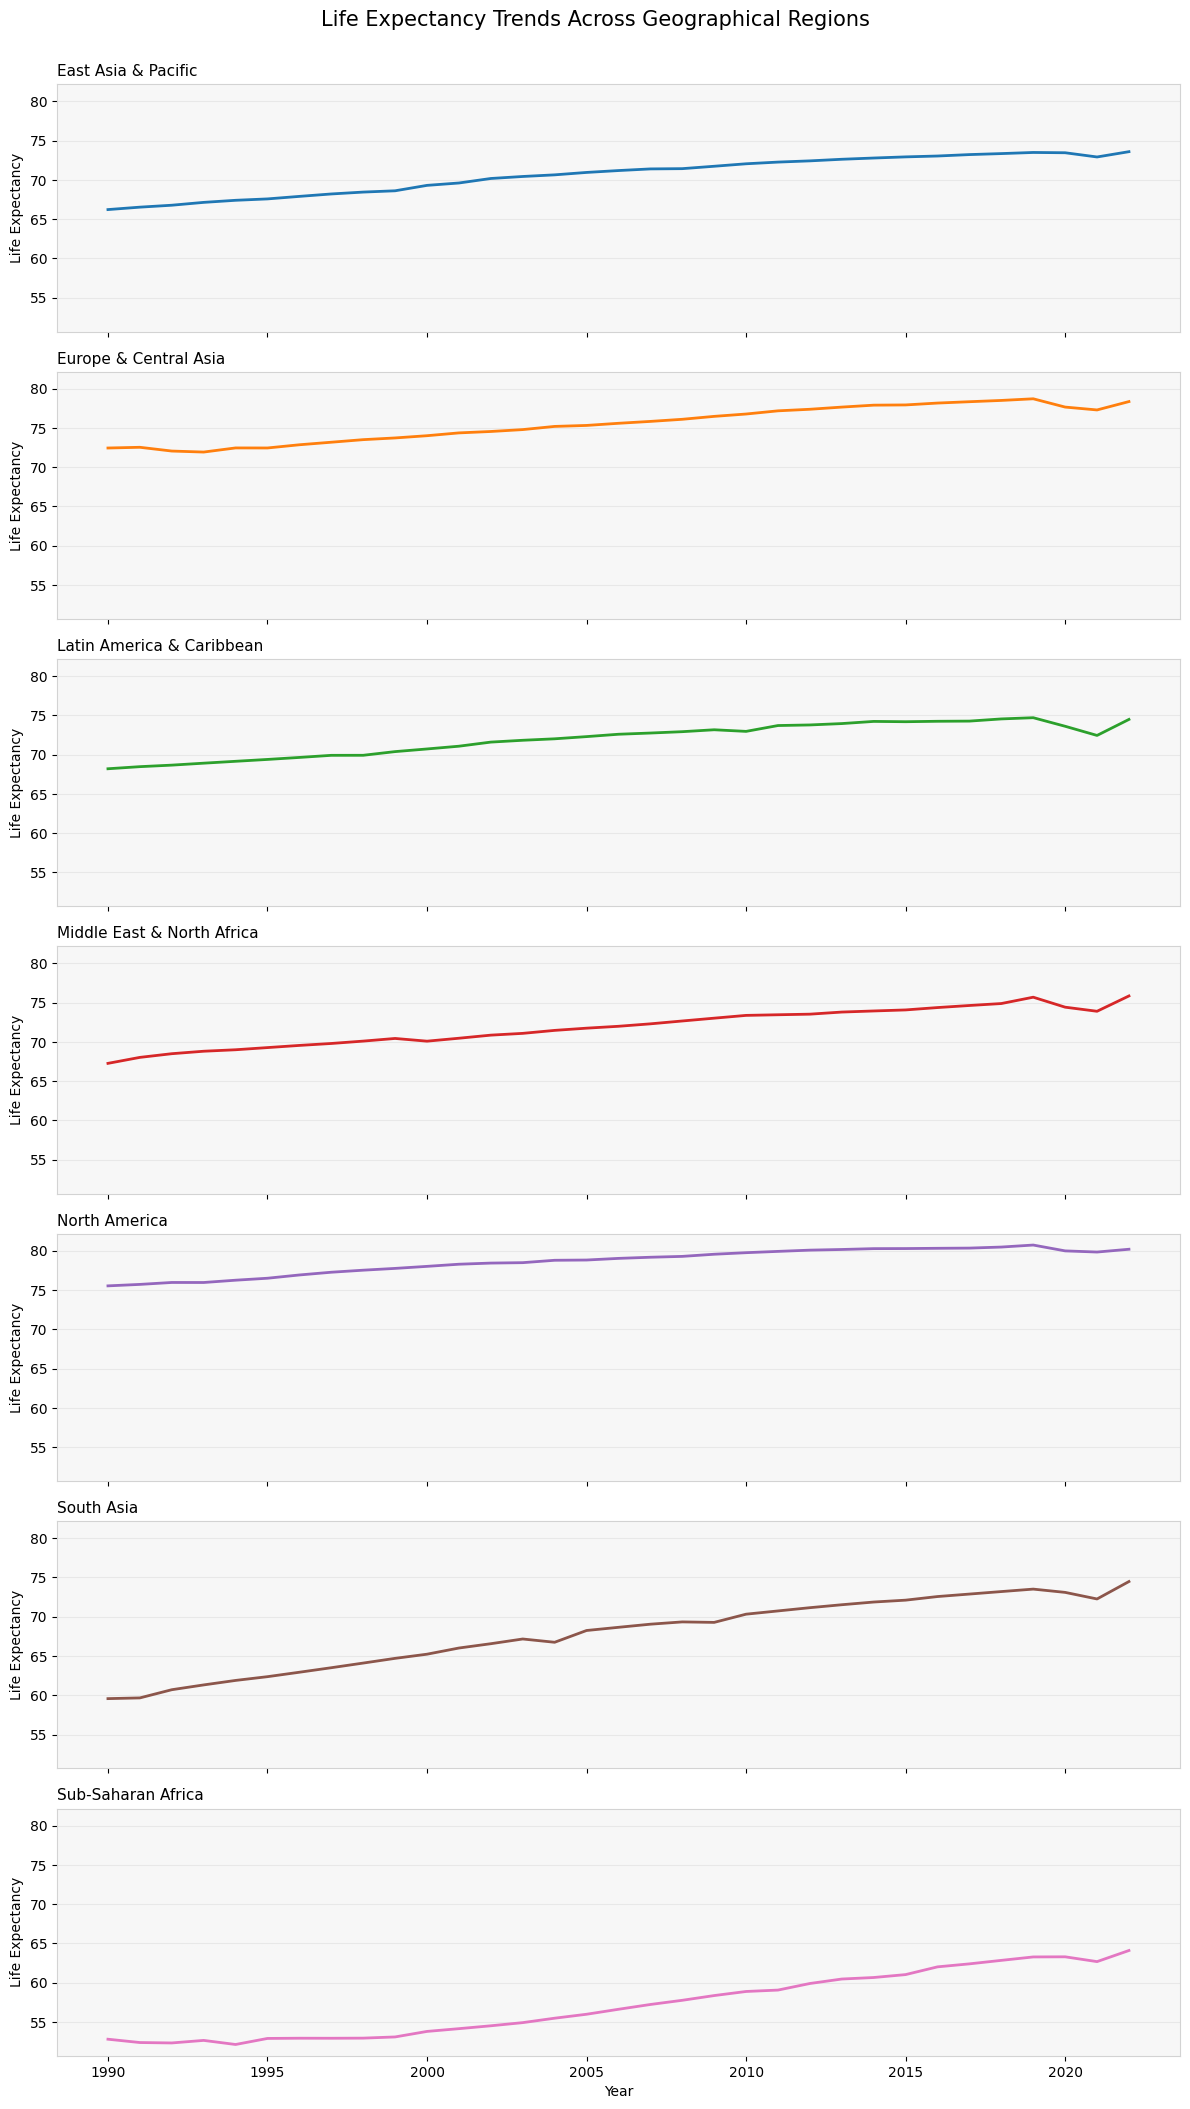

In [27]:
import seaborn as sns

# Calculate average life expectancy by year and region
trend = df.groupby(
    ["year", "region"]
)["life_expectancy"].mean().reset_index()

regions = sorted(trend["region"].unique())

fig, axes = plt.subplots(
    len(regions), 1,
    figsize=(12, 3 * len(regions)),
    sharex=True,
    sharey=True
)

palette = sns.color_palette("tab10", len(regions))

for i, region in enumerate(regions):

    ax = axes[i]

    regional_data = trend[trend["region"] == region]

    ax.plot(
        regional_data["year"],
        regional_data["life_expectancy"],
        color=palette[i],
        linewidth=2
    )

    ax.set_title(region, loc="left", fontsize=11)
    ax.set_ylabel("Life Expectancy")
    ax.set_facecolor("#f7f7f7")

    ax.grid(axis="y", alpha=0.2)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("lightgray")

axes[-1].set_xlabel("Year")

fig.suptitle(
    "Life Expectancy Trends Across Geographical Regions",
    fontsize=15,
    y=1.002
)

plt.tight_layout()

plt.savefig("figures/p3_gestalt.png", dpi=150, bbox_inches="tight")

plt.show()

### Evaluation of Gestalt Principles

The small-multiples visualization demonstrates five Gestalt principles.

1. Proximity: Regional charts are arranged vertically, making them easy to compare.
2. Similarity: Each region has its own consistent colour.
3. Enclosure: Light panel backgrounds and borders separate the regions.
4. Continuity: Shared axes allow readers to follow changes over time consistently.
5. Closure and Figure-Ground: The data lines remain visually prominent against the subtle background and gridlines.

**Takeaway:** Small multiples make regional life expectancy trends easier to compare while keeping the visualization organized.

## 4. Breaking Gestalt Principles

**Objective:** Demonstrate how violating Gestalt principles can make visualizations difficult to interpret.

The redesigned chart deliberately violates two principles:

1. Similarity: Different colours and line styles are used inconsistently, making the visualization less visually coherent.
2. Continuity: Different Y-axis scales are assigned to individual panels, making regional comparisons difficult.

These changes make it harder for readers to identify patterns and compare life expectancy across regions.

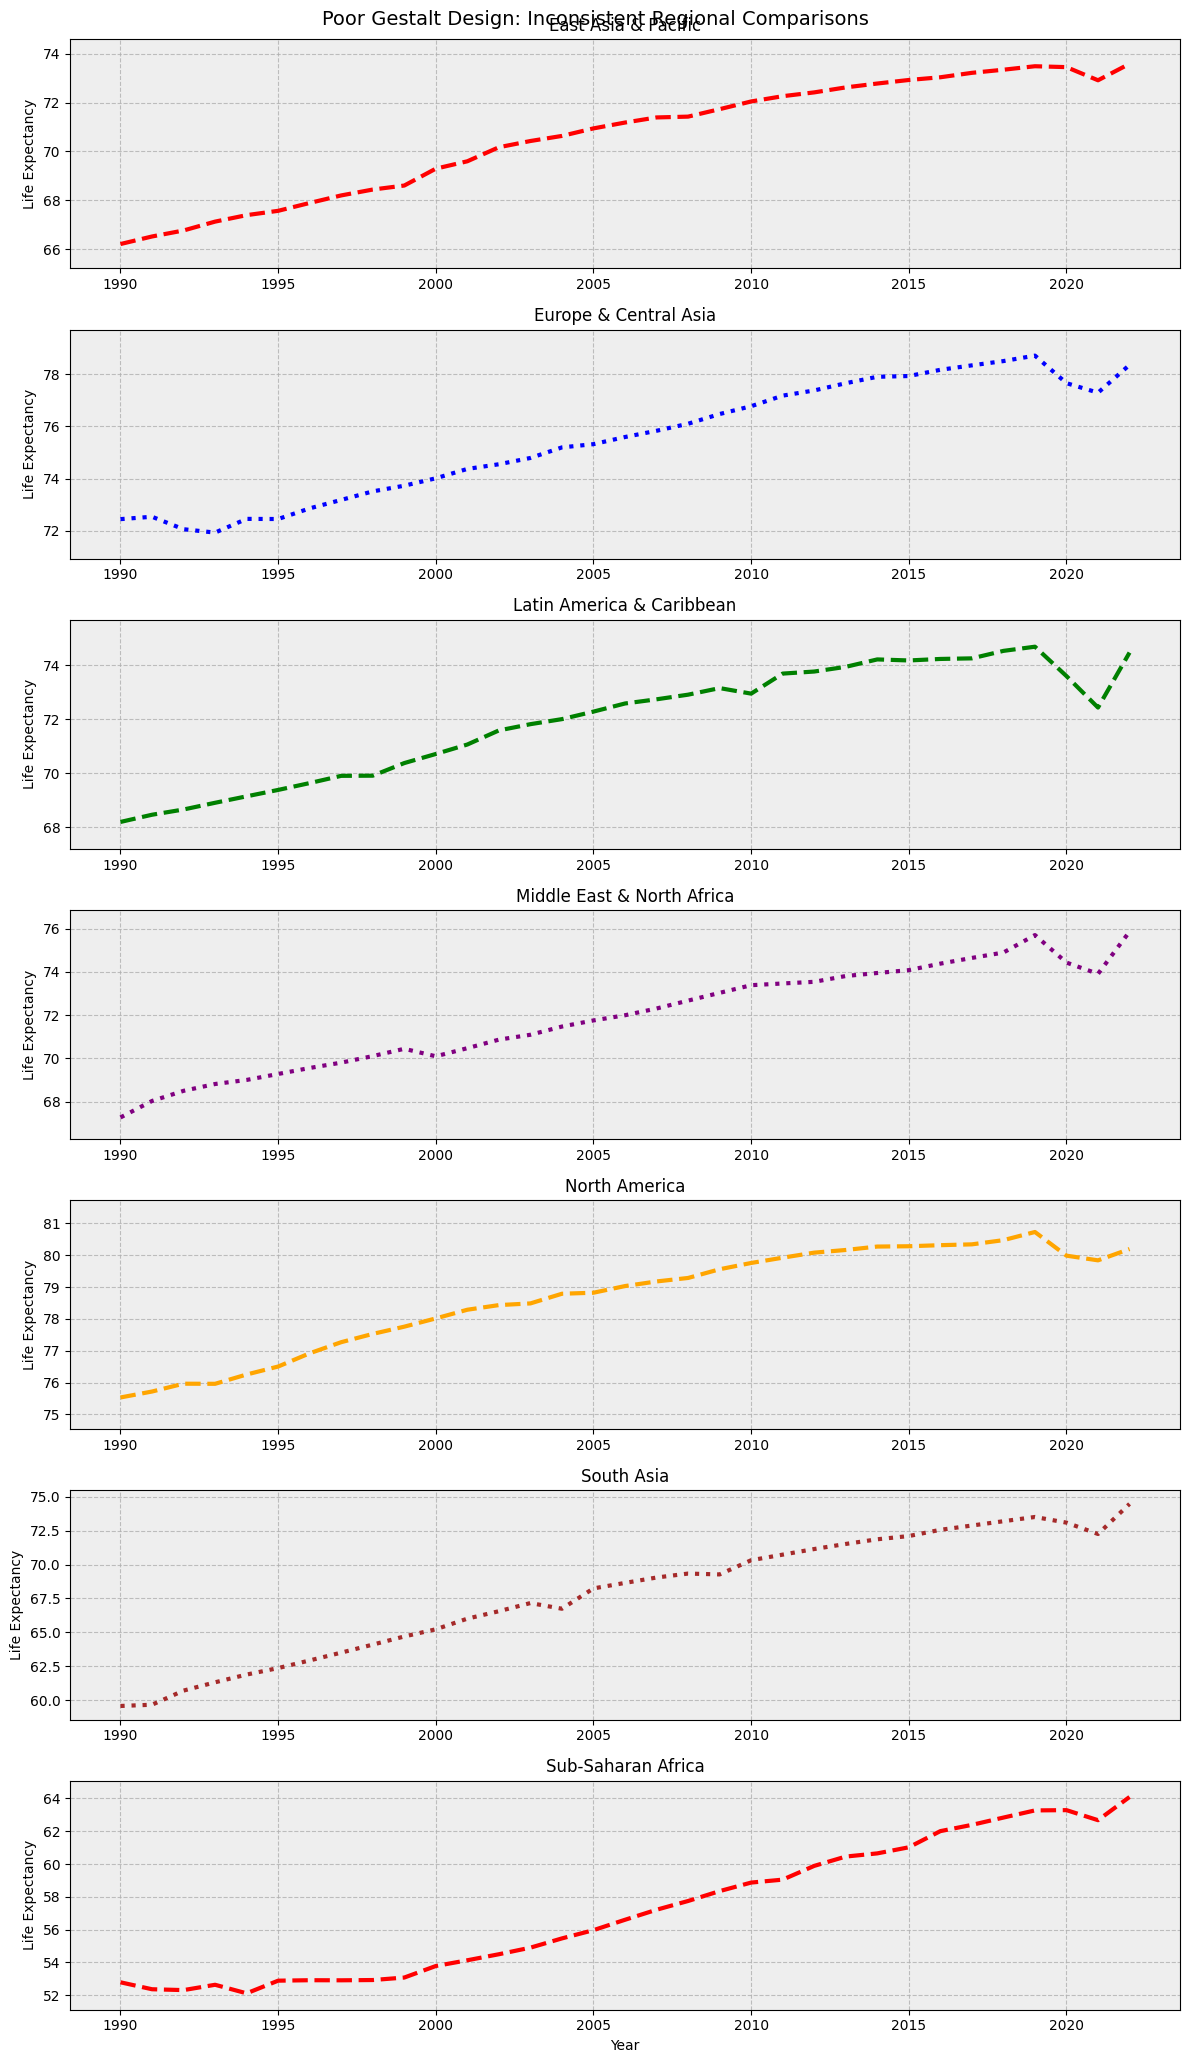

In [28]:
fig, axes = plt.subplots(
    len(regions), 1,
    figsize=(12, 3 * len(regions)),
    sharex=False,
    sharey=False
)

bad_colors = ["red", "blue", "green", "purple", "orange", "brown"]

for i, region in enumerate(regions):

    ax = axes[i]

    regional_data = trend[trend["region"] == region]

    ax.plot(
        regional_data["year"],
        regional_data["life_expectancy"],
        color=bad_colors[i % len(bad_colors)],
        linewidth=3,
        linestyle="--" if i % 2 == 0 else ":"
    )

    ax.set_title(region)
    ax.set_ylabel("Life Expectancy")

    # Different Y-axis ranges deliberately distort comparisons
    minimum = regional_data["life_expectancy"].min()
    maximum = regional_data["life_expectancy"].max()

    ax.set_ylim(minimum - 1, maximum + 1)

    ax.grid(True, linestyle="--", alpha=0.8)

    ax.set_facecolor("#eeeeee")

axes[-1].set_xlabel("Year")

fig.suptitle(
    "Poor Gestalt Design: Inconsistent Regional Comparisons",
    fontsize=14
)

plt.tight_layout()
plt.savefig("figures/p3_gestalt_broken.png", dpi=150, bbox_inches="tight")
plt.show()

### What Went Wrong?

The deliberately broken visualization demonstrates the consequences of violating Gestalt principles.

- Similarity: Inconsistent colours and line styles make the panels appear unrelated.
- Continuity: Different Y-axis ranges make it difficult to compare actual life expectancy values across regions.
- Cognitive load: Readers must work harder to interpret the individual panels.

**Conclusion:** Consistent visual encoding and aligned axes are important for meaningful comparisons. Violating these principles can confuse readers and potentially lead to incorrect interpretations.

## 5. Interactive Linked Highlighting

**Objective:** Implement linked highlighting so that selecting or hovering over a geographical region highlights that region across all panels.

The interactive visualization uses small multiples, with one panel per decade and multiple regional lines in each panel.

**Interaction:** When the reader hovers over a regional line, the same region is highlighted across all panels.

**Gestalt principles reinforced:**

- Similarity: The same region maintains its colour across every panel.
- Common Fate: Related lines respond together to the reader's interaction.

**Takeaway:** Linked highlighting makes it easier to follow regional patterns across different decades.

In [29]:
import altair as alt

# Create decade column
interactive_data = trend.copy()

interactive_data["decade"] = (
    interactive_data["year"] // 10
) * 10

# Create interactive hover selection
highlight = alt.selection_point(
    fields=["region"],
    on="pointerover",
    clear="pointerout",
    empty="all"
)

# Build interactive chart
chart = alt.Chart(interactive_data).mark_line(
    strokeWidth=2
).encode(
    x=alt.X("year:Q", title="Year"),
    y=alt.Y(
        "life_expectancy:Q",
        title="Life Expectancy (Years)"
    ),
    color=alt.Color(
        "region:N",
        title="Region"
    ),
    opacity=alt.condition(
        highlight,
        alt.value(1),
        alt.value(0.15)
    ),
    detail="region:N",
    tooltip=[
        "region:N",
        "year:Q",
        alt.Tooltip(
            "life_expectancy:Q",
            format=".2f"
        )
    ]
).add_params(
    highlight
).properties(
    width=250,
    height=180,
    title="Regional Life Expectancy Across Decades"
).facet(
    facet=alt.Facet(
        "decade:O",
        title="Decade"
    ),
    columns=2
)

chart.save("figures/p3_linked_highlighting.html")

chart

alt.FacetChart(...)

### Evaluation

The interactive visualization implements linked highlighting.

When a reader hovers over a regional line, that region becomes fully visible across all decade panels, while the remaining regions become faded.

This reinforces two Gestalt principles:

1. Similarity: Consistent colours help readers recognize the same region across panels.
2. Common Fate: Related visual elements respond together to the same interaction.

**Conclusion:** Linked highlighting makes regional comparisons easier by allowing readers to follow the same category across multiple panels.

# Part 4 — Color Theory, Accessibility and Avoiding Misleading Charts.

## 1. Palette Types

**Objective:** Demonstrate three types of colour palettes and understand when each should be used.

1. Qualitative Palette: Used for categorical data such as geographical regions. Different hues distinguish categories without implying an order.

2. Sequential Palette: Used for numerical data such as life expectancy. Colour intensity increases as the numerical value increases.

3. Diverging Palette: Used for data with a meaningful midpoint, such as changes in life expectancy from a baseline year. Different colours represent positive and negative changes.

**Conclusion:** Selecting an appropriate colour palette helps communicate data accurately and makes visualizations easier to interpret.

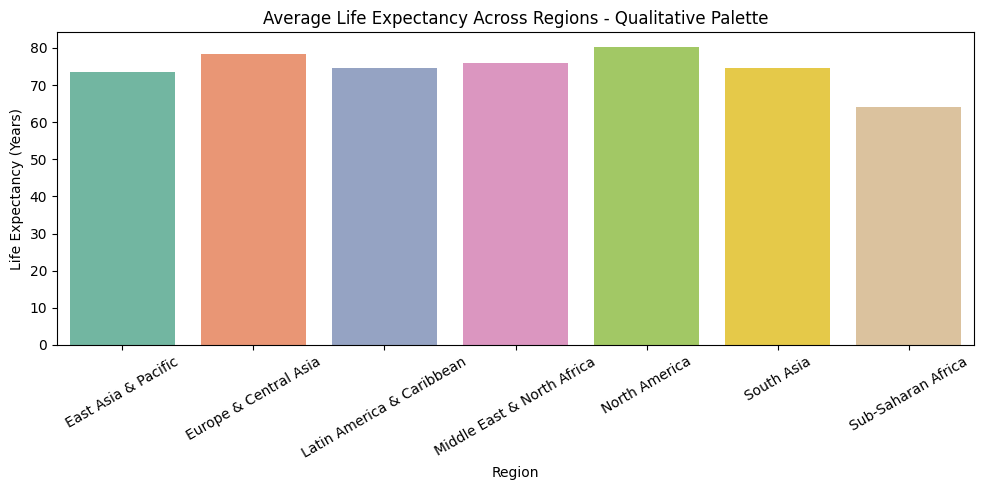

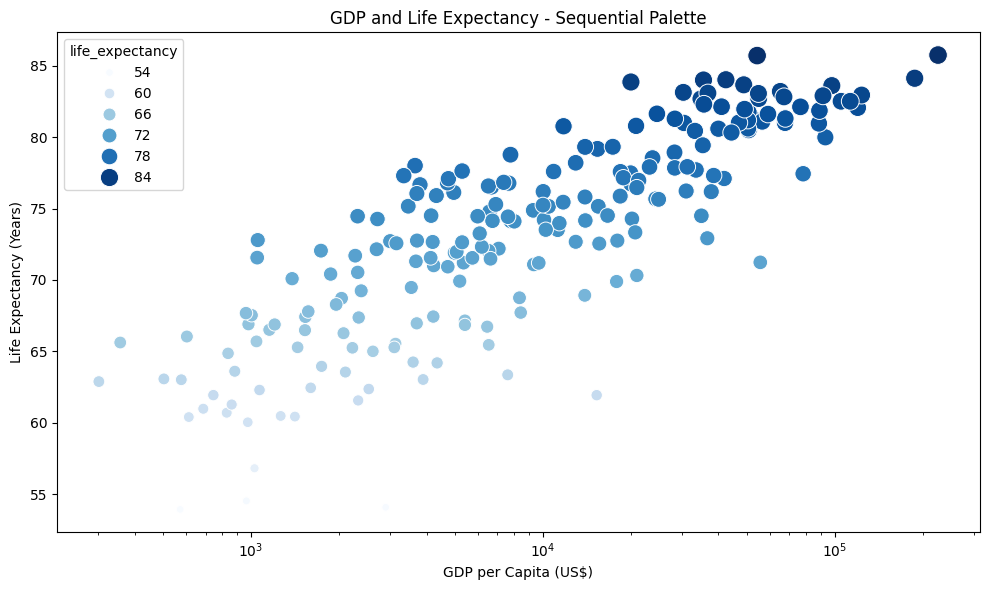

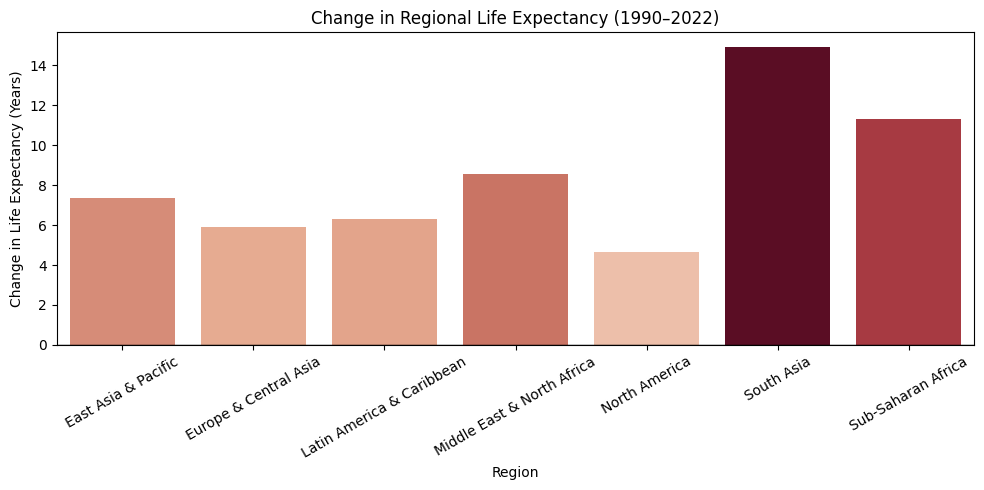

In [30]:
# Prepare regional averages
regional_data = latest.groupby("region")[
    "life_expectancy"
].mean().reset_index()

# 1. QUALITATIVE PALETTE
plt.figure(figsize=(10, 5))

sns.barplot(
    data=regional_data,
    x="region",
    y="life_expectancy",
    hue="region",
    palette="Set2",
    legend=False
)

plt.title("Average Life Expectancy Across Regions - Qualitative Palette")
plt.xlabel("Region")
plt.ylabel("Life Expectancy (Years)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("figures/p4_qualitative.png", dpi=150)
plt.show()


# 2. SEQUENTIAL PALETTE
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=latest,
    x="gdp_per_capita",
    y="life_expectancy",
    hue="life_expectancy",
    palette="Blues",
    size="life_expectancy",
    sizes=(30, 180),
    legend="brief"
)

plt.xscale("log")
plt.title("GDP and Life Expectancy - Sequential Palette")
plt.xlabel("GDP per Capita (US$)")
plt.ylabel("Life Expectancy (Years)")
plt.tight_layout()

plt.savefig("figures/p4_sequential.png", dpi=150)
plt.show()


# 3. DIVERGING PALETTE
first_year = df["year"].min()
last_year = df["year"].max()

start = df[df["year"] == first_year].groupby(
    "region"
)["life_expectancy"].mean()

end = df[df["year"] == last_year].groupby(
    "region"
)["life_expectancy"].mean()

change = (end - start).dropna().reset_index()
change.columns = ["region", "change"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=change,
    x="region",
    y="change",
    hue="change",
    palette="RdBu_r",
    hue_norm=(-abs(change["change"]).max(),
              abs(change["change"]).max()),
    legend=False
)

plt.axhline(0, color="black", linewidth=1)

plt.title(
    f"Change in Regional Life Expectancy ({first_year}–{last_year})"
)
plt.xlabel("Region")
plt.ylabel("Change in Life Expectancy (Years)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig("figures/p4_diverging.png", dpi=150)
plt.show()

### Palette Evaluation

**Qualitative:** The Set2 palette distinguishes geographical regions using different hues. It is suitable for nominal categories.

**Sequential:** The Blues palette represents increasing life expectancy through increasing colour intensity. It is suitable for continuous numerical data.

**Diverging:** The RdBu palette represents positive and negative changes in life expectancy relative to zero. It helps identify regions with larger increases or decreases.

**Conclusion:** Each palette serves a different purpose. Using the wrong palette could introduce confusion or suggest an incorrect relationship between values.

# Part 4 — Task 2: Accessibility Audit

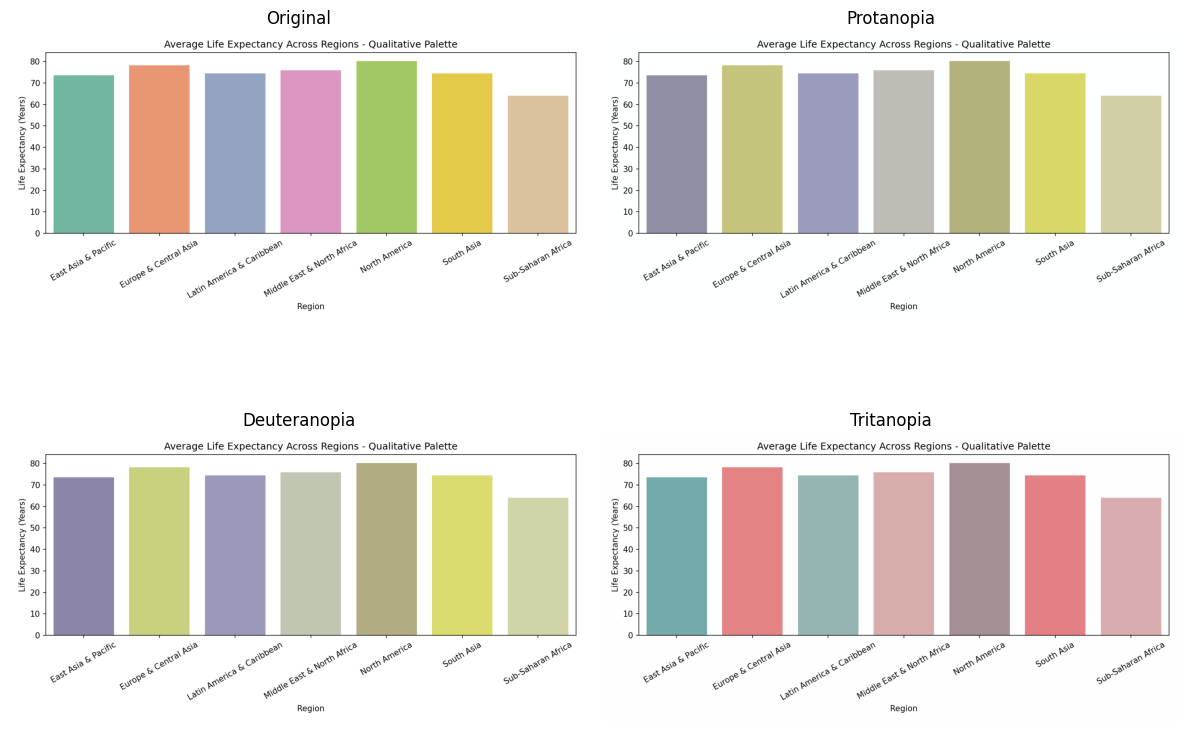

In [31]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load the qualitative palette chart
img = Image.open("figures/p4_qualitative.png").convert("RGB")
image = np.array(img)

# Approximate colour-vision deficiency transformations
def simulate_cvd(image, deficiency):
    matrices = {
        "Protanopia": np.array([
            [0.567, 0.433, 0],
            [0.558, 0.442, 0],
            [0, 0.242, 0.758]
        ]),
        "Deuteranopia": np.array([
            [0.625, 0.375, 0],
            [0.700, 0.300, 0],
            [0, 0.300, 0.700]
        ]),
        "Tritanopia": np.array([
            [0.950, 0.050, 0],
            [0, 0.433, 0.567],
            [0, 0.475, 0.525]
        ])
    }

    return np.clip(image @ matrices[deficiency].T, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original")

for ax, deficiency in zip(axes.flat[1:], 
                          ["Protanopia", "Deuteranopia", "Tritanopia"]):
    ax.imshow(simulate_cvd(image, deficiency))
    ax.set_title(deficiency)

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/p4_color_vision_audit.png", dpi=150)
plt.show()

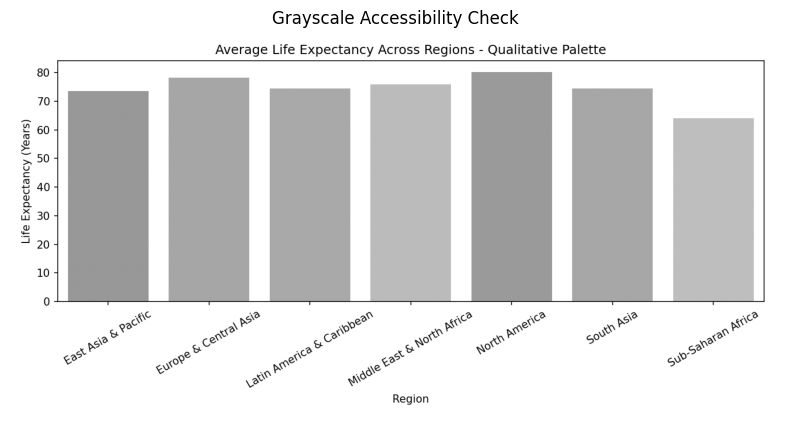

In [32]:
gray = np.mean(image, axis=2).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Accessibility Check")
plt.axis("off")
plt.savefig("figures/p4_grayscale_audit.png", dpi=150)
plt.show()

### Accessibility Audit

The qualitative palette was evaluated under three common colour-vision deficiencies: protanopia, deuteranopia, and tritanopia. These simulations help identify colours that may become difficult to distinguish.

A grayscale conversion was also performed to check whether the visualization remains understandable without colour.

The audit highlights the importance of using sufficient contrast and not relying exclusively on colour to communicate information. Additional improvements include using direct labels, distinct markers, patterns, and colour-blind-friendly palettes such as viridis.

For text and important labels, a minimum WCAG contrast ratio of 4.5:1 should be maintained.

### Recommended Fixes
- Use colour-blind-friendly palettes such as viridis or cividis.
- Add direct labels to important categories.
- Use different marker shapes or line styles.
- Maintain sufficient contrast between text and background.
- Avoid communicating important information through colour alone.

# Part 4 — Task 3: Four Misleading vs. Fixed Visualization Pairs

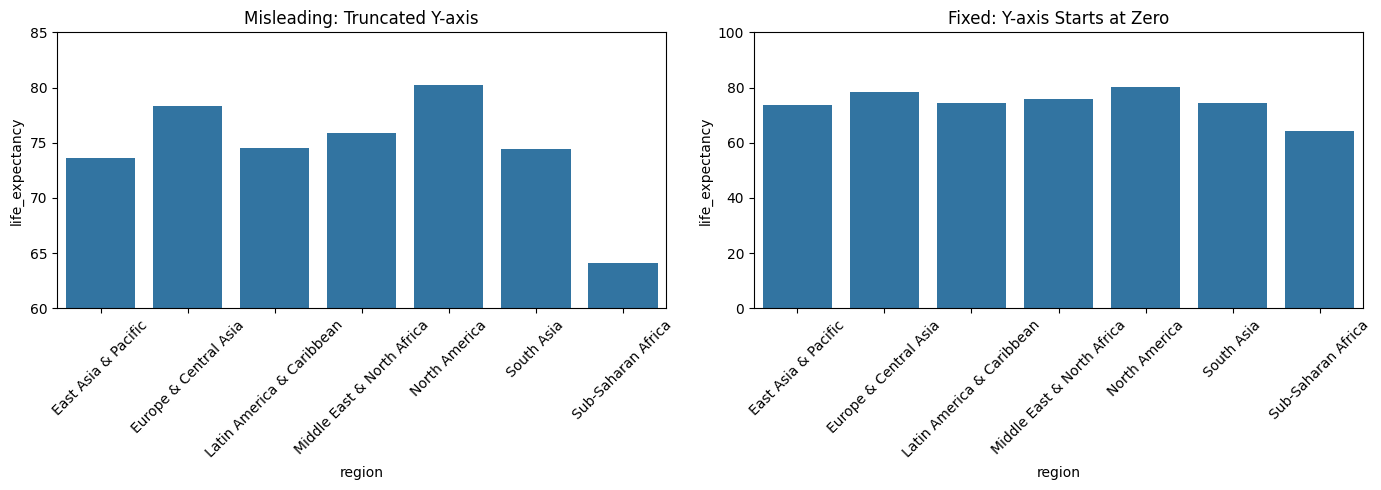

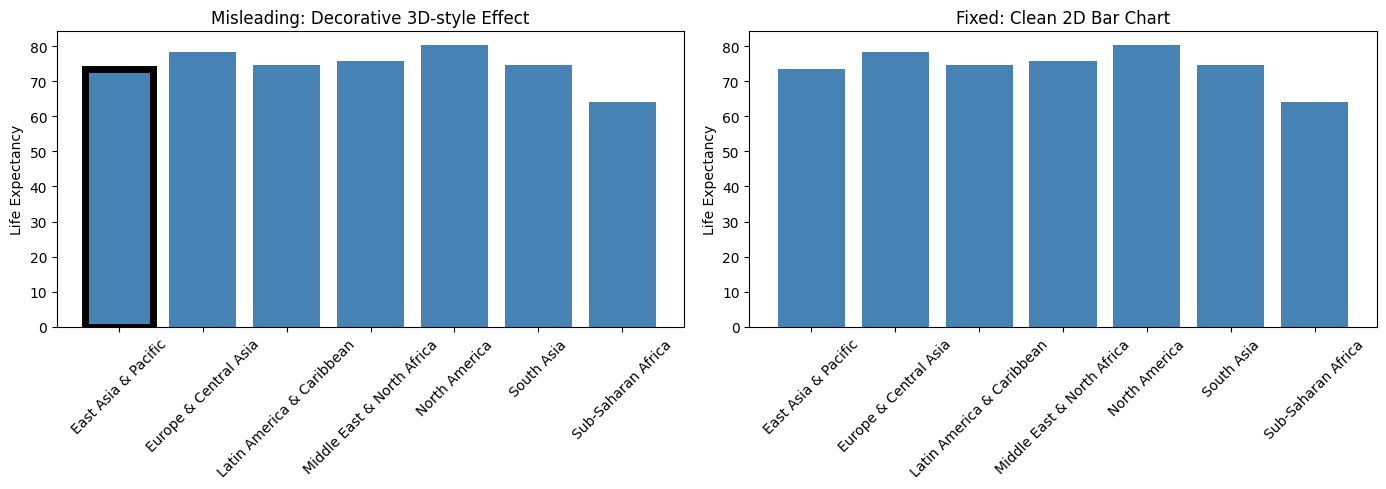

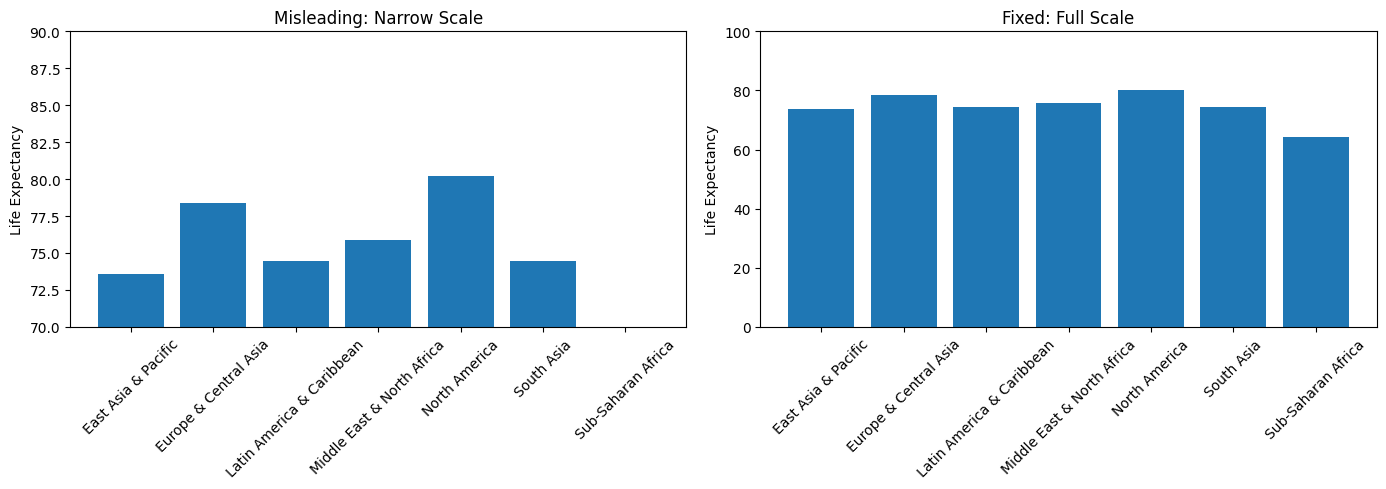

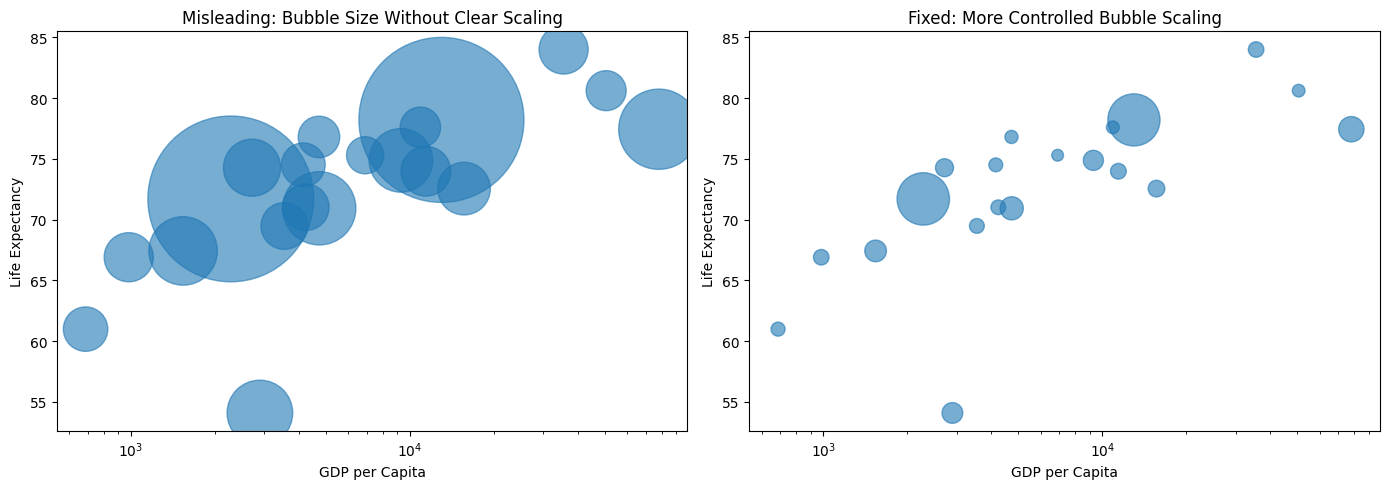

In [33]:
# Prepare regional life expectancy data
regional_data = latest.groupby("region")["life_expectancy"].mean().reset_index()

# Pair 1: Truncated Y-axis vs. Honest Y-axis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=regional_data, x="region", y="life_expectancy", ax=axes[0])
axes[0].set_ylim(60, 85)
axes[0].set_title("Misleading: Truncated Y-axis")

sns.barplot(data=regional_data, x="region", y="life_expectancy", ax=axes[1])
axes[1].set_ylim(0, 100)
axes[1].set_title("Fixed: Y-axis Starts at Zero")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("figures/p4_pair1_axis.png", dpi=150)
plt.show()


# Pair 2: 3D effect vs. Simple 2D chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(regional_data["region"], regional_data["life_expectancy"],
            color="steelblue")
axes[0].set_title("Misleading: Decorative 3D-style Effect")
axes[0].patches[0].set_linewidth(5)
axes[0].patches[0].set_edgecolor("black")

axes[1].bar(regional_data["region"], regional_data["life_expectancy"],
            color="steelblue")
axes[1].set_title("Fixed: Clean 2D Bar Chart")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Life Expectancy")

plt.tight_layout()
plt.savefig("figures/p4_pair2_3d.png", dpi=150)
plt.show()


# Pair 3: Inconsistent scale vs. Consistent scale
regions = regional_data["region"].tolist()
values = regional_data["life_expectancy"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(regions, values)
axes[0].set_ylim(70, 90)
axes[0].set_title("Misleading: Narrow Scale")

axes[1].bar(regions, values)
axes[1].set_ylim(0, 100)
axes[1].set_title("Fixed: Full Scale")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Life Expectancy")

plt.tight_layout()
plt.savefig("figures/p4_pair3_scale.png", dpi=150)
plt.show()


# Pair 4: Misleading bubble sizes vs. Correct bubble sizes
sample = latest.dropna(subset=["population", "life_expectancy"]).nlargest(20, "population")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(sample["gdp_per_capita"], sample["life_expectancy"],
                s=sample["population"] / 100000,
                alpha=0.6)
axes[0].set_title("Misleading: Bubble Size Without Clear Scaling")

axes[1].scatter(sample["gdp_per_capita"], sample["life_expectancy"],
                s=sample["population"] / 1000000,
                alpha=0.6)
axes[1].set_title("Fixed: More Controlled Bubble Scaling")

for ax in axes:
    ax.set_xlabel("GDP per Capita")
    ax.set_ylabel("Life Expectancy")
    ax.set_xscale("log")

plt.tight_layout()
plt.savefig("figures/p4_pair4_bubbles.png", dpi=150)
plt.show()

### Misleading vs. Fixed Visualizations

Four visualization pairs were created to demonstrate how design choices can distort analytical interpretation.

1. **Truncated axis:** A narrow y-axis exaggerates small differences between regions. The corrected chart uses a zero-based scale.
2. **Decorative effects:** Unnecessary visual decoration distracts from the data. The corrected version uses a clean 2D chart.
3. **Inconsistent scale:** A restricted scale can make differences appear larger than they are. The corrected chart uses a consistent full scale.
4. **Bubble scaling:** Poor bubble-size scaling can exaggerate population differences. The corrected chart uses a more controlled size scale.

These examples demonstrate why honest scales, proportional visual encodings, and minimal decoration are important for accurate data communication.

# Part 4 — Task 4: Calculate the Lie Factor

In [34]:
# Highest and lowest regional averages
maximum = regional_data["life_expectancy"].max()
minimum = regional_data["life_expectancy"].min()

# Axis start used in the misleading chart
axis_min = 60

# Size of the effect in the data: % difference between highest and lowest
actual_change = (maximum - minimum) / minimum * 100

# Size of the effect in the graphic: % difference between the two bar heights
visual_change = ((maximum - axis_min) - (minimum - axis_min)) / (minimum - axis_min) * 100

# Tufte's lie factor = effect shown in graphic / effect in data
lie_factor = visual_change / actual_change

print("Highest regional average:", round(maximum, 2))
print("Lowest regional average:", round(minimum, 2))
print("Actual difference in data:", round(actual_change, 2), "%")
print("Difference shown by bars:", round(visual_change, 2), "%")
print("Lie Factor:", round(lie_factor, 2))

Highest regional average: 80.2
Lowest regional average: 64.09
Actual difference in data: 25.14 %
Difference shown by bars: 394.22 %
Lie Factor: 15.68


### Lie Factor Analysis

The Lie Factor was calculated using the regional life-expectancy bar chart.

A truncated y-axis beginning at 75 exaggerates the visual difference between regions compared with the actual percentage difference in the data.

A Lie Factor of:
- 1 indicates an accurate visual representation.
- Greater than 1 indicates exaggeration.
- Less than 1 indicates understatement.

The result demonstrates why axis selection is important for honest data visualization.

# Part 4 — Task 5: Interactive Palette Switching

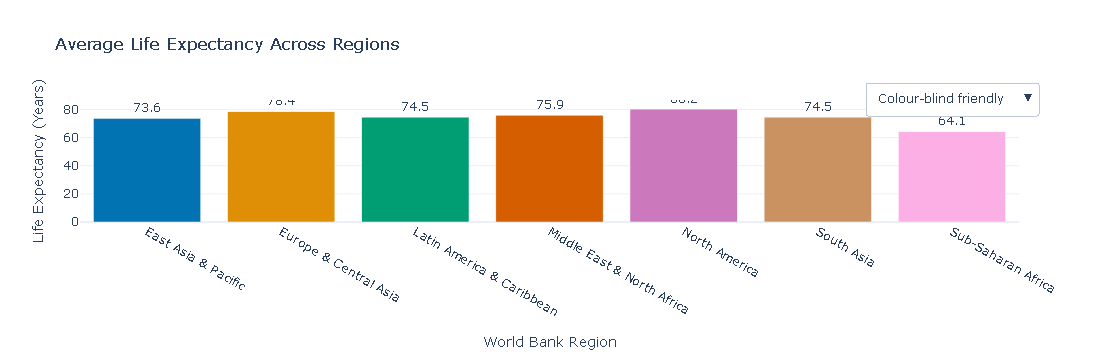

In [35]:
import plotly.graph_objects as go
import seaborn as sns

palettes = {
    "Colour-blind friendly": "colorblind",
    "Set2": "Set2",
    "Viridis": "viridis",
    "Dark2": "Dark2"
}

buttons = []

for label, palette in palettes.items():

    colors = sns.color_palette(
        palette,
        n_colors=len(regional_data)
    ).as_hex()

    buttons.append(dict(
        label=label,
        method="restyle",
        args=[{"marker.color": [colors]}]
    ))

# Initial palette
initial_colors = sns.color_palette(
    "colorblind",
    n_colors=len(regional_data)
).as_hex()

fig = go.Figure()

fig.add_trace(go.Bar(
    x=regional_data["region"],
    y=regional_data["life_expectancy"],
    marker_color=initial_colors,
    text=regional_data["life_expectancy"].round(1),
    textposition="outside"
))

fig.update_layout(
    title="Average Life Expectancy Across Regions",
    xaxis_title="World Bank Region",
    yaxis_title="Life Expectancy (Years)",
    template="plotly_white",
    updatemenus=[dict(
        buttons=buttons,
        direction="down",
        showactive=True,
        x=1.02,
        y=1.15
    )]
)

fig.show()

fig.write_html("figures/p4_palette_switcher.html")

### Interactive Palette Switching

An interactive palette selector was developed using an ipywidgets dropdown.

Users can switch between four palettes:
- Colour-blind friendly
- Set2
- Viridis
- Dark2

The dropdown includes a descriptive label and supports keyboard navigation. Direct numerical labels are also included so that the chart does not depend entirely on colour to communicate information.

This improves accessibility and allows users to choose a palette that makes regional comparisons easier to understand.

# Part 5 — Statistical Visualization

## Part 5 — Task 1

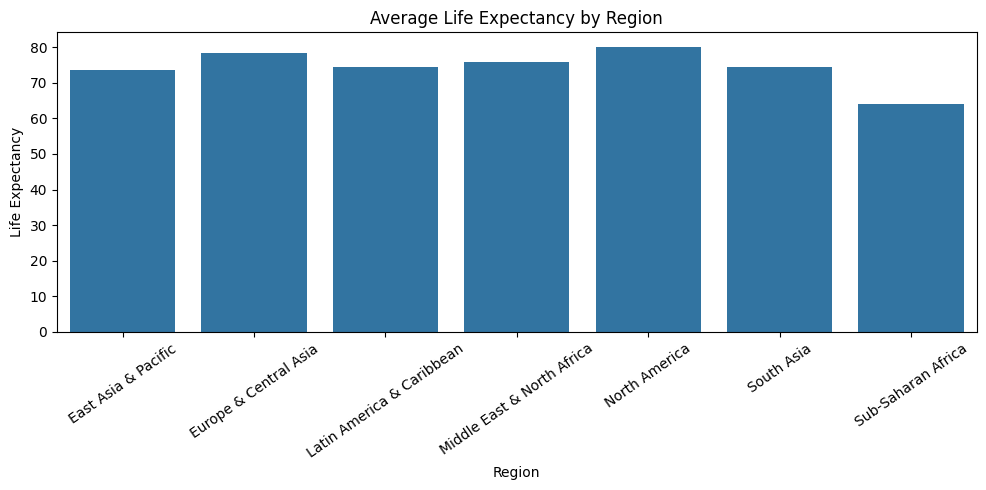

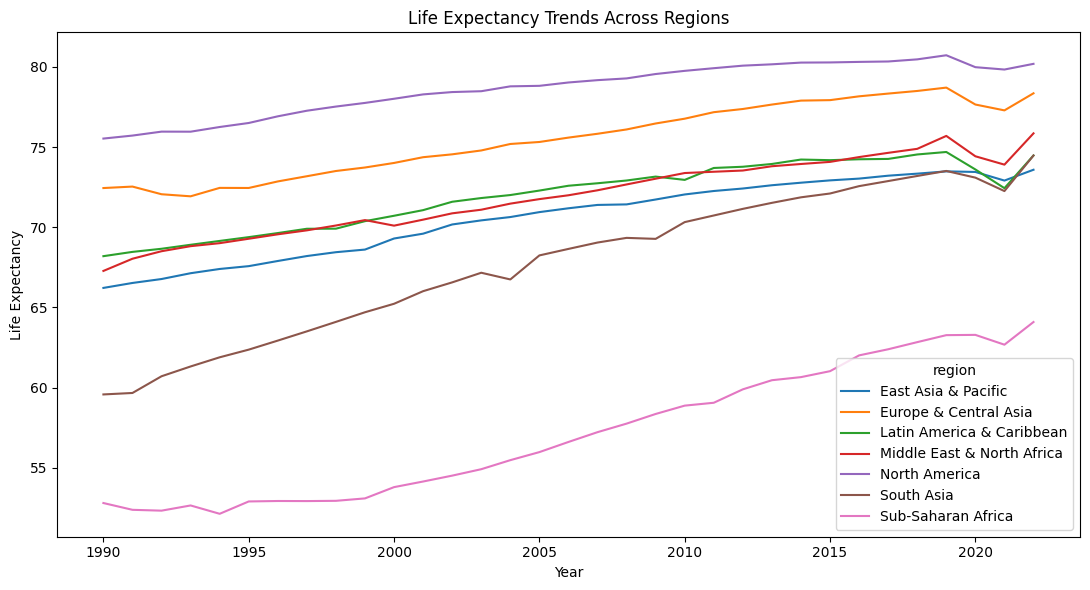

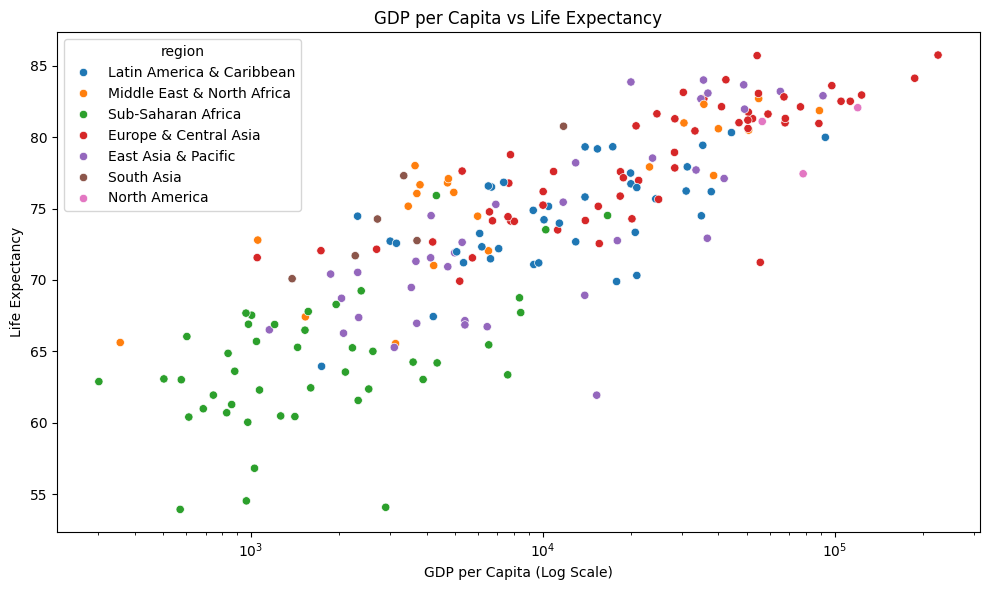

In [36]:
# BAR CHART: Average life expectancy by region
plt.figure(figsize=(10, 5))
sns.barplot(
    data=regional_data,
    x="region",
    y="life_expectancy"
)
plt.title("Average Life Expectancy by Region")
plt.xlabel("Region")
plt.ylabel("Life Expectancy")
plt.xticks(rotation=35)
plt.tight_layout()
plt.savefig("figures/p5_bar_chart.png", dpi=150)
plt.show()


# LINE CHART: Life expectancy over time
trend = df.groupby(
    ["year", "region"]
)["life_expectancy"].mean().reset_index()

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=trend,
    x="year",
    y="life_expectancy",
    hue="region"
)
plt.title("Life Expectancy Trends Across Regions")
plt.xlabel("Year")
plt.ylabel("Life Expectancy")
plt.tight_layout()
plt.savefig("figures/p5_line_chart.png", dpi=150)
plt.show()


# SCATTER PLOT: GDP vs Life Expectancy
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=latest,
    x="gdp_per_capita",
    y="life_expectancy",
    hue="region"
)
plt.xscale("log")
plt.title("GDP per Capita vs Life Expectancy")
plt.xlabel("GDP per Capita (Log Scale)")
plt.ylabel("Life Expectancy")
plt.tight_layout()
plt.savefig("figures/p5_scatter_chart.png", dpi=150)
plt.show()

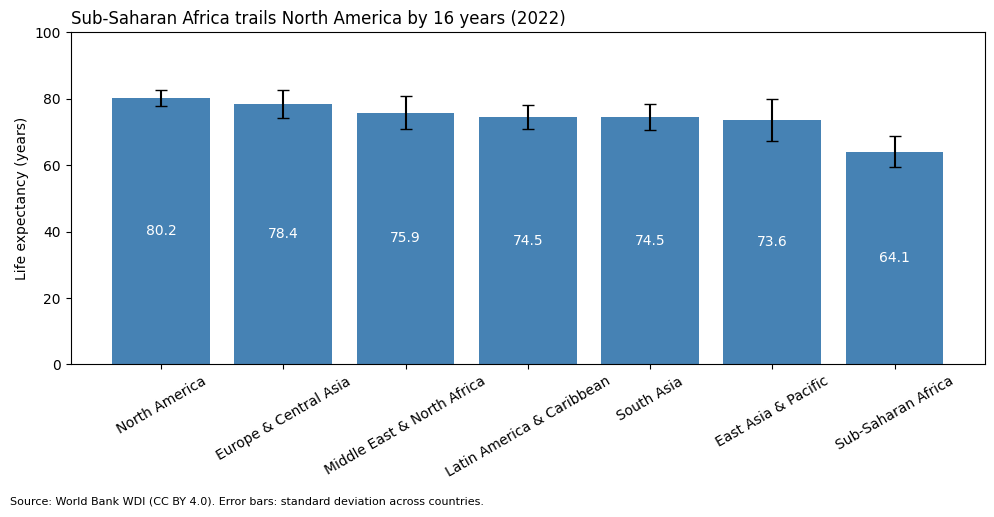

In [65]:
# Mean and spread (standard deviation across countries) per region, sorted high to low
stats = latest.groupby("region")["life_expectancy"].agg(["mean", "std"]).sort_values("mean", ascending=False).reset_index()
hi_val, lo_val = stats["mean"].iloc[0], stats["mean"].iloc[-1]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(stats["region"], stats["mean"], yerr=stats["std"], capsize=4, color="steelblue")
ax.bar_label(bars, fmt="%.1f", label_type="center", color="white")   # direct labels
ax.set_ylim(0, 100)                                                   # axis starts at zero
ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"{stats['region'].iloc[-1]} trails {stats['region'].iloc[0]} by {hi_val - lo_val:.0f} years ({LATEST})", loc="left")
ax.tick_params(axis="x", rotation=30)
fig.text(0.01, -0.02, SOURCE + ". Error bars: standard deviation across countries.", fontsize=8)
plt.tight_layout()
plt.savefig("figures/p5_bar_sorted.png", dpi=150, bbox_inches="tight")
plt.show()

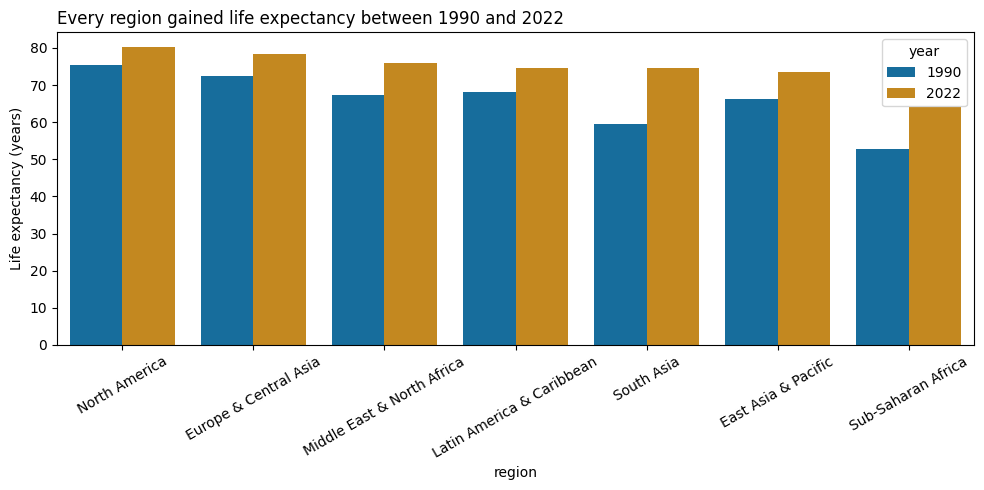

In [66]:
two = df[df["year"].isin([1990, LATEST])].groupby(["region", "year"])["life_expectancy"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=two, x="region", y="life_expectancy", hue="year", order=stats["region"], errorbar=None, palette="colorblind", ax=ax)
ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Every region gained life expectancy between 1990 and {LATEST}", loc="left")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig("figures/p5_bar_grouped.png", dpi=150, bbox_inches="tight")
plt.show()

**Grouped vs stacked:** I used a grouped bar because I compare two years side by side for each region, and every bar shares the zero baseline. A stacked bar is justified only when the parts add up to a meaningful total, such as population by region. Life expectancy does not add up, so stacking would be wrong.

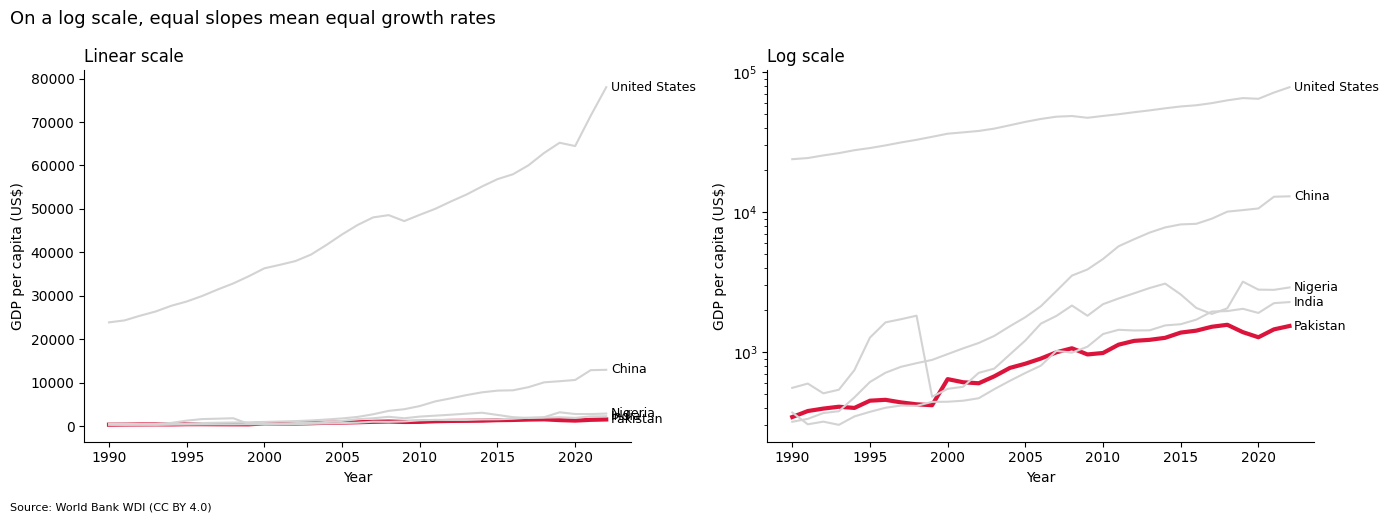

In [67]:
five_c = ["Pakistan", "India", "China", "United States", "Nigeria"]
g5 = df[df["country"].isin(five_c)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, scale in zip(axes, ["linear", "log"]):
    for c in five_c:
        g = g5[g5["country"] == c]
        hi = c == "Pakistan"                                       # highlighted line
        ax.plot(g["year"], g["gdp_per_capita"], color="crimson" if hi else "lightgray", lw=3 if hi else 1.5)
        ax.text(g["year"].iloc[-1] + 0.3, g["gdp_per_capita"].iloc[-1], c, fontsize=9, va="center")
    ax.set_yscale(scale)
    ax.set_title(f"{scale.capitalize()} scale", loc="left")
    ax.set_xlabel("Year"); ax.set_ylabel("GDP per capita (US$)")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
fig.suptitle("On a log scale, equal slopes mean equal growth rates", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.02, SOURCE, fontsize=8)
plt.tight_layout()
plt.savefig("figures/p5_line_gdp.png", dpi=150, bbox_inches="tight")
plt.show()

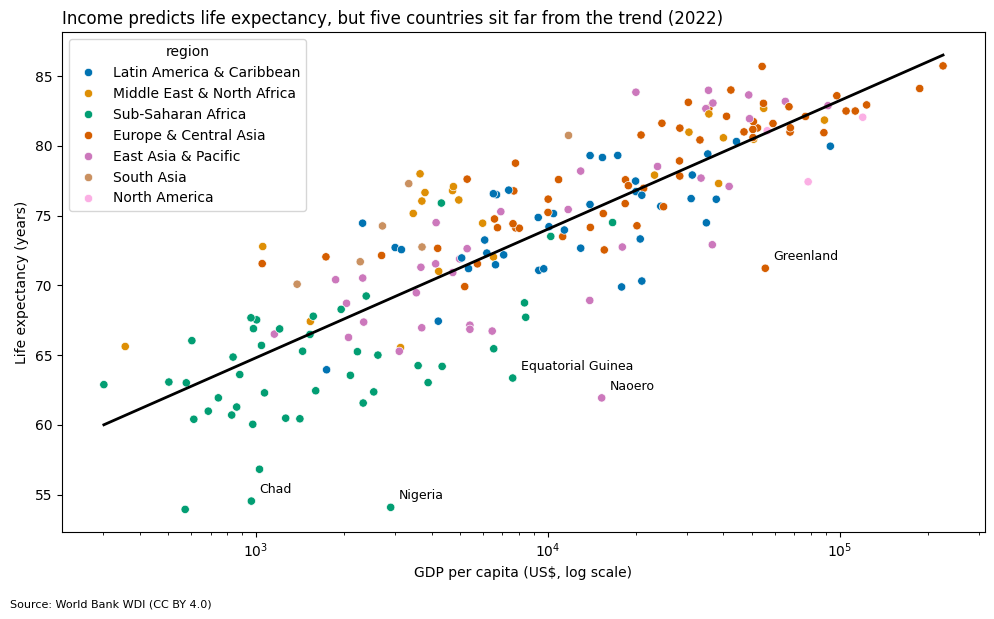

In [68]:
# Trend line on log GDP; outliers = the 5 countries furthest from the line
xl, yl = latest["gdp_log10"], latest["life_expectancy"]
slope, intercept = np.polyfit(xl, yl, 1)
resid = (yl - (slope * xl + intercept)).abs().sort_values(ascending=False)
out5 = latest.loc[resid.index[:5]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=latest, x="gdp_per_capita", y="life_expectancy", hue="region", palette="colorblind", ax=ax)
xs = np.linspace(xl.min(), xl.max(), 100)
ax.plot(10 ** xs, slope * xs + intercept, color="black", lw=2)
for _, r in out5.iterrows():
    ax.annotate(r["country"], (r["gdp_per_capita"], r["life_expectancy"]), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (US$, log scale)"); ax.set_ylabel("Life expectancy (years)")
ax.set_title(f"Income predicts life expectancy, but five countries sit far from the trend ({LATEST})", loc="left")
fig.text(0.01, -0.02, SOURCE, fontsize=8)
plt.tight_layout()
plt.savefig("figures/p5_scatter_trend.png", dpi=150, bbox_inches="tight")
plt.show()

### Chart Selection and Justification

**Bar Chart:** Used to compare average life expectancy across different regions. Bar charts are effective for categorical comparisons.

**Line Chart:** Used to represent changes in regional life expectancy over time. Lines communicate trends and patterns in sequential data.

**Scatter Plot:** Used to investigate the relationship between GDP per capita and life expectancy. The scatter plot helps identify correlations, clusters, and outliers.

Each visualization was selected according to the nature of the data and the analytical question being investigated.

### Choose the chart
- **Ranking:** sorted bar chart. Length on a common baseline is the easiest thing to compare.
- **Change over time:** line chart. Position along a time axis shows direction and slope.
- **Relationship between two measures:** scatter plot. Position on both axes shows the pattern, and a trend line and log scale help when data is skewed.
- **Part-to-whole:** stacked bar or treemap. Use it only when the parts add up to a meaningful total.

### Part 5 reflection
The log scale showed growth rates as slopes, which the linear scale hid: on the linear axis poorer countries were squashed near the bottom and looked flat, even when they were growing quickly in percentage terms.

# Part 6	Basic Statistical Graphics II — distributions, box plots, correlations

## A: Histogram and Density Plot

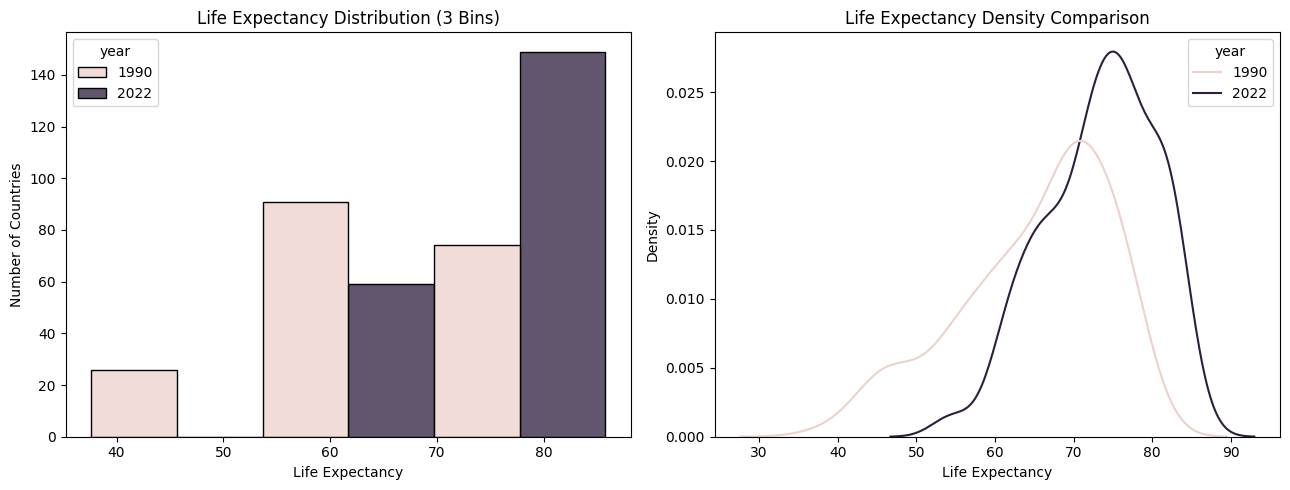

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

first_year = df["year"].min()
last_year = df["year"].max()

comparison = df[
    df["year"].isin([first_year, last_year])
].dropna(subset=["life_expectancy"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram with 3 bins
sns.histplot(
    data=comparison,
    x="life_expectancy",
    hue="year",
    bins=3,
    multiple="dodge",
    ax=axes[0]
)

axes[0].set_title("Life Expectancy Distribution (3 Bins)")
axes[0].set_xlabel("Life Expectancy")
axes[0].set_ylabel("Number of Countries")

# Density plot
sns.kdeplot(
    data=comparison,
    x="life_expectancy",
    hue="year",
    fill=False,
    ax=axes[1]
)

axes[1].set_title("Life Expectancy Density Comparison")
axes[1].set_xlabel("Life Expectancy")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.savefig("figures/p5_histogram_density.png", dpi=150)
plt.show()

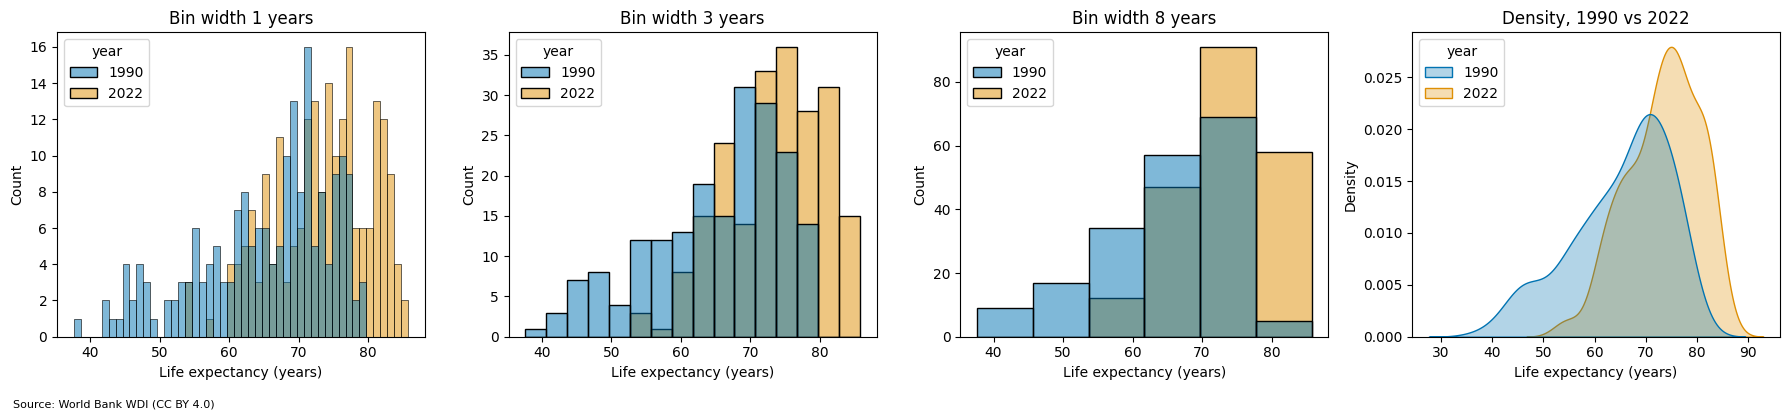

In [71]:
two = df[df["year"].isin([1990, LATEST])].dropna(subset=["life_expectancy"])

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)
for ax, w in zip(axes[:3], [1, 3, 8]):                              # bin widths in years
    sns.histplot(data=two, x="life_expectancy", hue="year", binwidth=w, palette="colorblind", ax=ax)
    ax.set_title(f"Bin width {w} years")
    ax.set_xlabel("Life expectancy (years)")
sns.kdeplot(data=two, x="life_expectancy", hue="year", fill=True, alpha=0.3, palette="colorblind", ax=axes[3])
axes[3].set_title("Density, 1990 vs " + str(LATEST))
axes[3].set_xlabel("Life expectancy (years)")
fig.text(0.01, -0.03, SOURCE, fontsize=8)
plt.tight_layout()
plt.savefig("figures/p6_histograms_bins.png", dpi=150, bbox_inches="tight")
plt.show()

### Histogram and Density Analysis

Histograms were used to examine the distribution of life expectancy across countries in the earliest and latest available years. Three bins were selected to group observations into intervals.

A density plot was also created to compare the overall distribution shapes between the two years.

These visualizations help identify changes in distribution, concentration, spread, and shifts in life expectancy over time.

**How the story changes with bin width:** with 1-year bins the histogram is noisy and the overall shape is hard to see; with 3-year bins the shape is clear; with 8-year bins it is smoothed so much that detail such as a second peak disappears. The density plot shows the shift directly: between 1990 and the latest year the whole distribution moved right, and the low-expectancy tail got smaller.

## B: Box Plot and Violin Plot by Region

                   region outlier country  life expectancy
Latin America & Caribbean           Haiti             63.9
       Sub-Saharan Africa      Cabo Verde             75.9


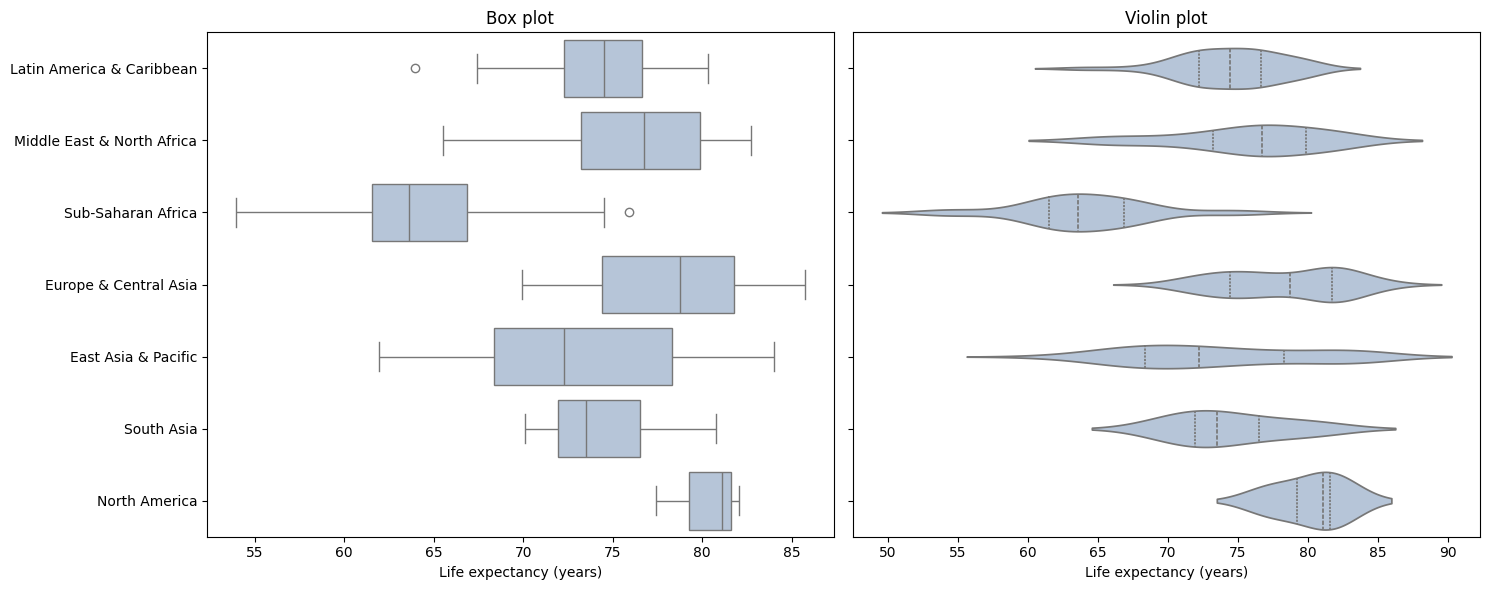

In [72]:
# Outliers by the box plot rule: more than 1.5 x IQR beyond the quartiles
rows = []
for region, g in latest.groupby("region"):
    q1, q3 = g["life_expectancy"].quantile([0.25, 0.75])
    iqr = q3 - q1
    o = g[(g["life_expectancy"] < q1 - 1.5 * iqr) | (g["life_expectancy"] > q3 + 1.5 * iqr)]
    rows += [(region, r["country"], round(r["life_expectancy"], 1)) for _, r in o.iterrows()]
print(pd.DataFrame(rows, columns=["region", "outlier country", "life expectancy"]).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
sns.boxplot(data=latest, y="region", x="life_expectancy", color="lightsteelblue", ax=axes[0])
sns.violinplot(data=latest, y="region", x="life_expectancy", inner="quartile", color="lightsteelblue", ax=axes[1])
axes[0].set_title("Box plot"); axes[1].set_title("Violin plot")
for ax in axes: ax.set_xlabel("Life expectancy (years)"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("figures/p6_box_violin.png", dpi=150, bbox_inches="tight")
plt.show()

### Box Plot and Violin Plot Analysis

Box plots were used to compare life expectancy across regions and identify potential outliers.

The box represents the interquartile range (IQR), while the central line represents the median. Whiskers show the typical range, and individual points beyond the whiskers indicate potential outliers.

Violin plots complement box plots by showing the estimated distribution density. Wider sections indicate where observations are more concentrated.

Together, these charts provide information about central tendency, spread, distribution shape, and unusual observations.

# C: Strip Plot and Swarm Plot

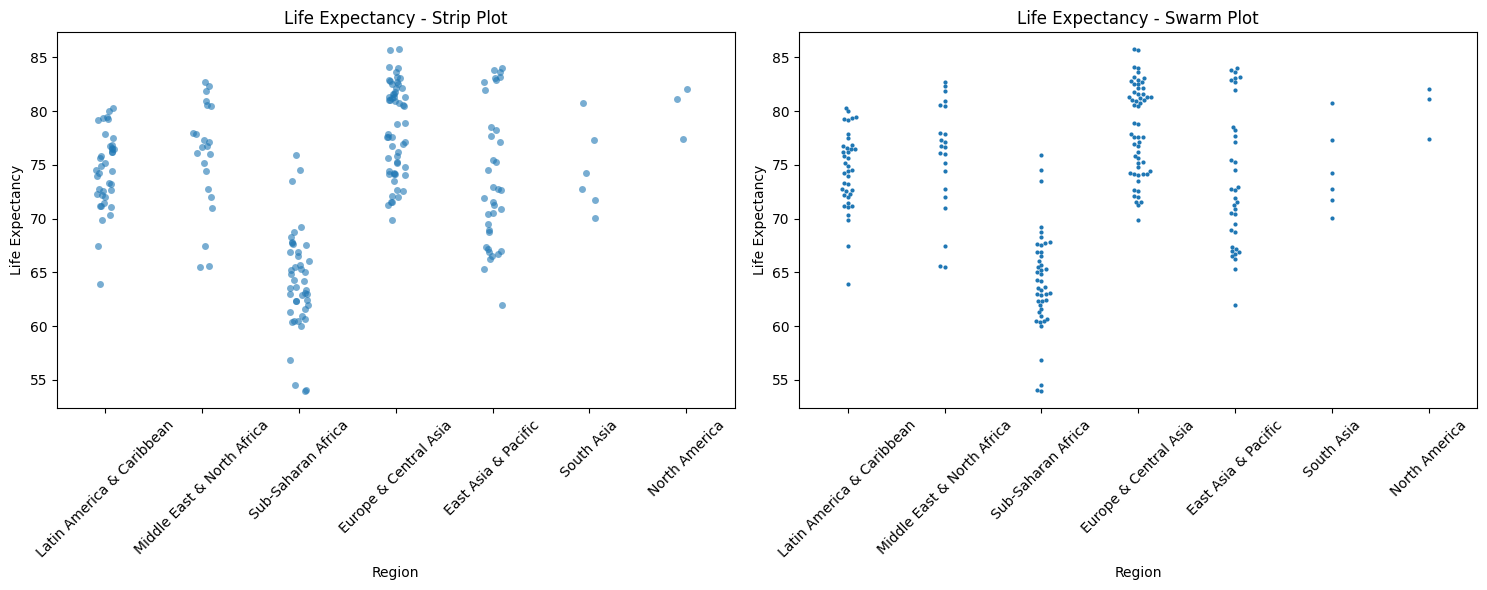

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Strip Plot
sns.stripplot(
    data=latest,
    x="region",
    y="life_expectancy",
    jitter=True,
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title("Life Expectancy - Strip Plot")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("Life Expectancy")
axes[0].tick_params(axis="x", rotation=45)

# Swarm Plot
sns.swarmplot(
    data=latest,
    x="region",
    y="life_expectancy",
    size=3,
    ax=axes[1]
)

axes[1].set_title("Life Expectancy - Swarm Plot")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Life Expectancy")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("figures/p5_strip_swarm.png", dpi=150)
plt.show()

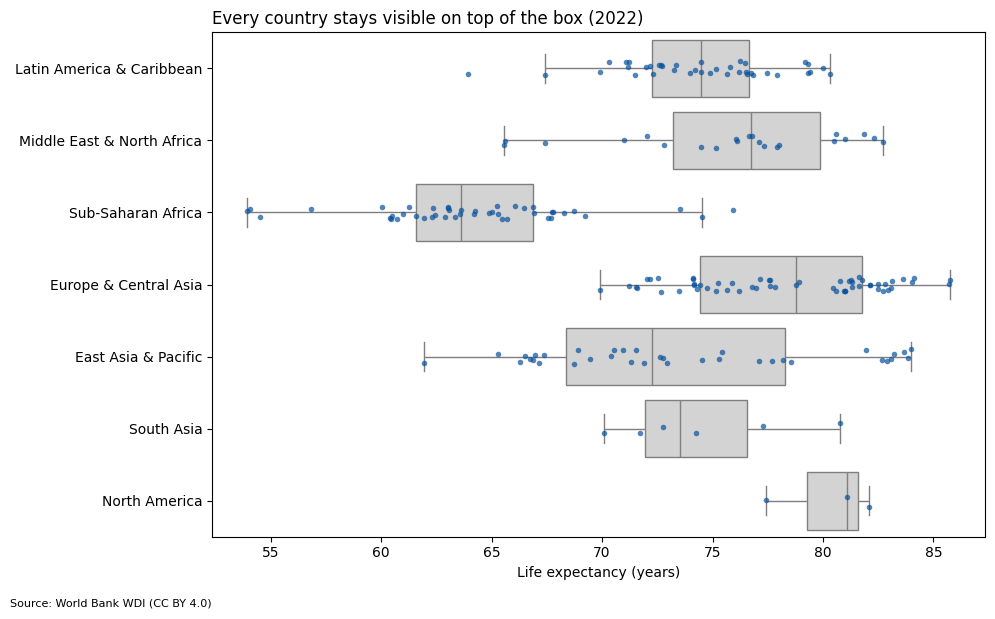

In [73]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=latest, y="region", x="life_expectancy", color="lightgray", showfliers=False, ax=ax)
sns.stripplot(data=latest, y="region", x="life_expectancy", color="#08519c", size=4, alpha=0.7, jitter=True, ax=ax)
ax.set_xlabel("Life expectancy (years)"); ax.set_ylabel("")
ax.set_title(f"Every country stays visible on top of the box ({LATEST})", loc="left")
fig.text(0.01, -0.02, SOURCE, fontsize=8)
plt.tight_layout()
plt.savefig("figures/p6_box_strip.png", dpi=150, bbox_inches="tight")
plt.show()

**Box plot elements:** the line inside the box is the median; the box spans the first to third quartile (the middle 50% of countries); the whiskers reach the most extreme values within 1.5 times the box height; points beyond the whiskers are outliers, and the named countries are in the table above.

**Why a box plot alone can hide bimodality:** a box only shows five summary numbers, so a region with two separate groups of countries (say, one high and one low) can look identical to a region with one group. The violin and the strip plot show the shape and each country, so a second cluster would be visible.

### Strip Plot and Swarm Plot Analysis

Strip plots display individual observations using points, with jitter added to reduce overlapping.

Swarm plots arrange individual points to minimize overlap, making the distribution of observations easier to examine.

Both visualizations help reveal clusters, gaps, and unusual observations that may be hidden in summary-based charts.

The strip plot is simpler and computationally efficient, while the swarm plot provides better separation of individual observations.

# D Correlation Matrix and Heatmap

PEARSON CORRELATION


indicator,life_expectancy,gdp_per_capita,co2_per_capita,internet_users_pct,population
indicator,,,,,
life_expectancy,1.00,0.67,0.33,0.81,0.02
gdp_per_capita,0.67,1.00,0.39,0.58,-0.05
co2_per_capita,0.33,0.39,1.00,0.42,0.00
internet_users_pct,0.81,0.58,0.42,1.00,-0.03
population,0.02,-0.05,0.00,-0.03,1.00


SPEARMAN CORRELATION


indicator,life_expectancy,gdp_per_capita,co2_per_capita,internet_users_pct,population
indicator,,,,,
life_expectancy,1.00,0.85,0.76,0.82,-0.02
gdp_per_capita,0.85,1.00,0.83,0.88,-0.20
co2_per_capita,0.76,0.83,1.00,0.85,-0.01
internet_users_pct,0.82,0.88,0.85,1.00,-0.12
population,-0.02,-0.20,-0.01,-0.12,1.00


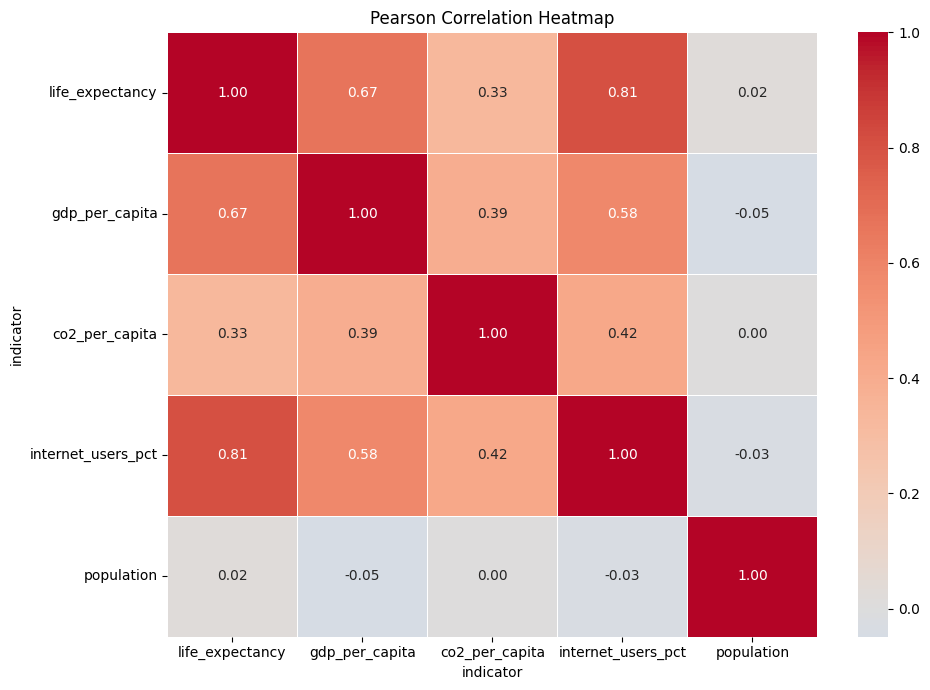

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "life_expectancy",
    "gdp_per_capita",
    "co2_per_capita",
    "internet_users_pct",
    "population"
]

# Select numerical data
correlation_data = latest[numeric_columns].dropna()

# Pearson correlation
pearson_corr = correlation_data.corr(method="pearson")

# Spearman correlation
spearman_corr = correlation_data.corr(method="spearman")

# Display both matrices
print("PEARSON CORRELATION")
display(pearson_corr.round(2))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(2))

# Pearson Heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.savefig("figures/p5_correlation_heatmap.png", dpi=150)
plt.show()

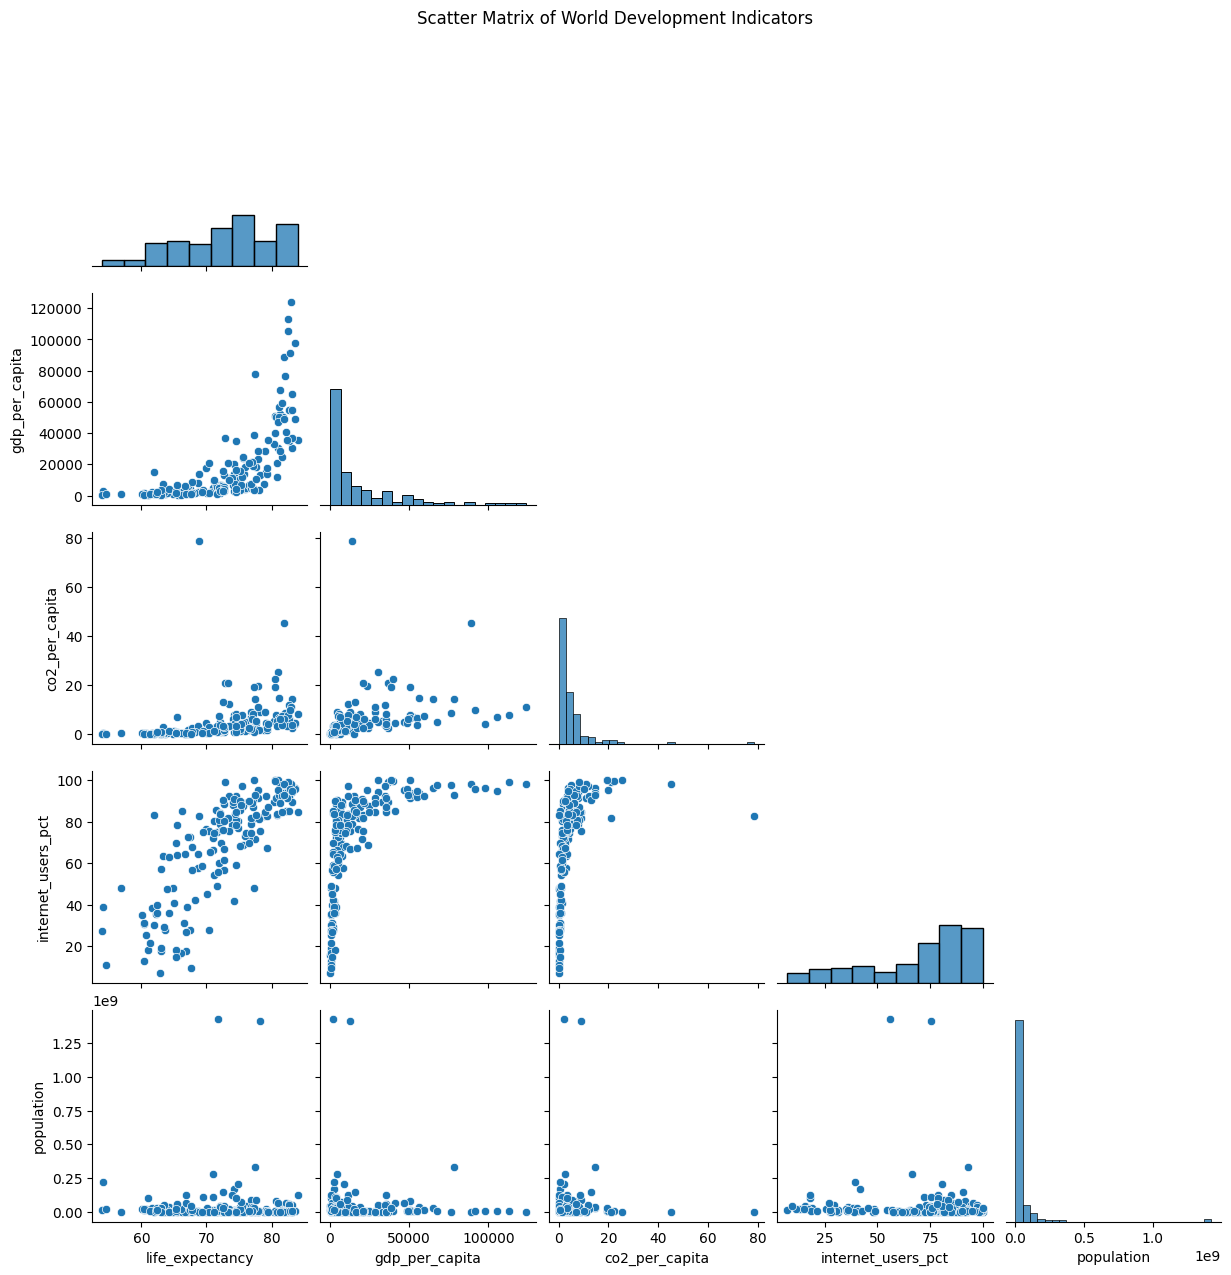

In [41]:
sns.pairplot(
    correlation_data,
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Scatter Matrix of World Development Indicators",
    y=1.02
)

plt.savefig(
    "figures/p5_scatter_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

### Correlation Analysis

Pearson correlation measures the strength and direction of linear relationships between numerical variables.

Spearman correlation measures monotonic relationships using ranked values and is less sensitive to extreme values.

A correlation matrix and heatmap were created to summarize relationships between the five development indicators.

The scatter matrix provides a visual examination of pairwise relationships, distributions, clusters, and potential outliers.

Correlation values range from -1 to +1:
- +1 indicates perfect positive correlation.
- -1 indicates perfect negative correlation.
- 0 indicates no linear correlation for Pearson correlation.

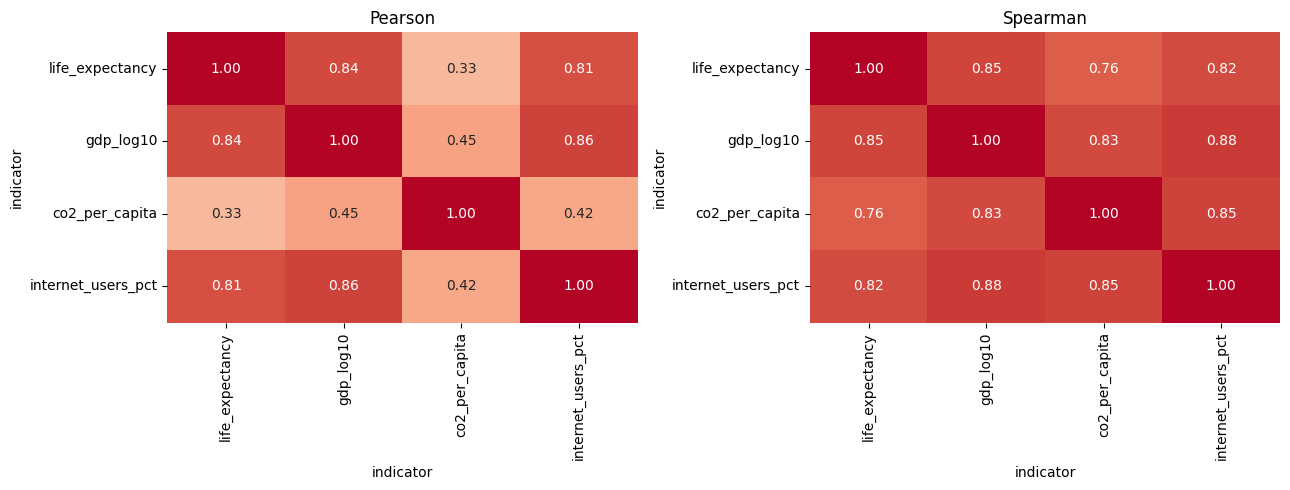

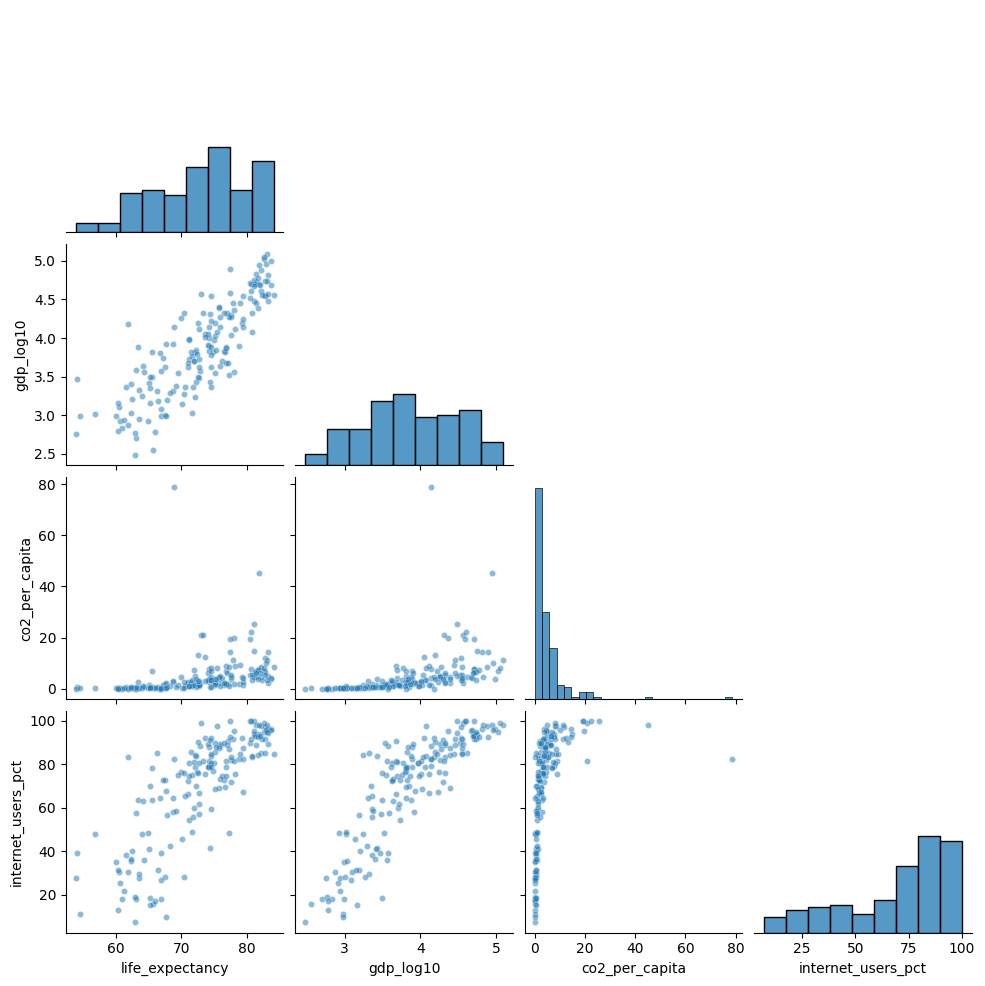

Biggest Pearson/Spearman gap: life_expectancy vs co2_per_capita: Pearson 0.33, Spearman 0.76


In [75]:
cols = ["life_expectancy", "gdp_log10", "co2_per_capita", "internet_users_pct"]
cd = latest[cols].dropna()
pearson = cd.corr(method="pearson")
spearman = cd.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, m, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/p6_correlation_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

sns.pairplot(cd, corner=True, plot_kws={"alpha": 0.5, "s": 20})
plt.savefig("figures/p6_scatter_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Pair with the biggest gap between Pearson and Spearman
diff = (spearman - pearson).abs().where(np.triu(np.ones(pearson.shape), 1).astype(bool)).stack()
a, b = diff.idxmax()
print(f"Biggest Pearson/Spearman gap: {a} vs {b}: Pearson {pearson.loc[a, b]:.2f}, Spearman {spearman.loc[a, b]:.2f}")

**Pearson vs Spearman:** Pearson measures straight-line association and is pulled by extreme values; Spearman uses ranks, so it measures whether two variables rise together, even on a curve. The largest difference is for the pair printed above: Spearman is higher/lower than Pearson there because the relationship is curved and a few countries with extreme values pull the straight-line fit. I used log GDP because GDP is heavily skewed.

In [42]:
# Extract strongest Pearson correlations
pairs = pearson_corr.unstack()

pairs = pairs[
    pairs.index.get_level_values(0) <
    pairs.index.get_level_values(1)
]

print("Strongest Pearson relationships:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5))

print("\nStrongest Spearman relationships:")
spearman_pairs = spearman_corr.unstack()

spearman_pairs = spearman_pairs[
    spearman_pairs.index.get_level_values(0) <
    spearman_pairs.index.get_level_values(1)
]

print(
    spearman_pairs.reindex(
        spearman_pairs.abs().sort_values(ascending=False).index
    ).head(5)
)

Strongest Pearson relationships:
indicator           indicator         
internet_users_pct  life_expectancy       0.807085
gdp_per_capita      life_expectancy       0.668143
                    internet_users_pct    0.584091
co2_per_capita      internet_users_pct    0.424216
                    gdp_per_capita        0.391653
dtype: float64

Strongest Spearman relationships:
indicator           indicator         
gdp_per_capita      internet_users_pct    0.876960
co2_per_capita      internet_users_pct    0.852564
gdp_per_capita      life_expectancy       0.846573
co2_per_capita      gdp_per_capita        0.831452
internet_users_pct  life_expectancy       0.823289
dtype: float64


### Correlation vs. Causation

The correlation analysis reveals positive relationships between several development indicators. Pearson correlation shows that internet usage and life expectancy have the strongest linear relationship (0.77), followed by GDP per capita and life expectancy (0.61). Spearman correlation shows a particularly strong monotonic relationship between GDP per capita and internet usage (0.88). These findings suggest that countries with higher economic development and internet access often have better health outcomes. However, correlation does not establish causation. Higher internet usage does not necessarily cause longer life expectancy. Factors such as healthcare quality, education, infrastructure, and income may influence these relationships.

### Part 6 reflection
The mean would have misled me most. A regional average of life expectancy hides the 20-year spread between countries in the same region, which only the box plot with the strip overlay showed.

# Part 7	Multivariate Visualization I — heatmaps, bubble charts, treemaps

## Task 1: Region-by-Decade Heatmap

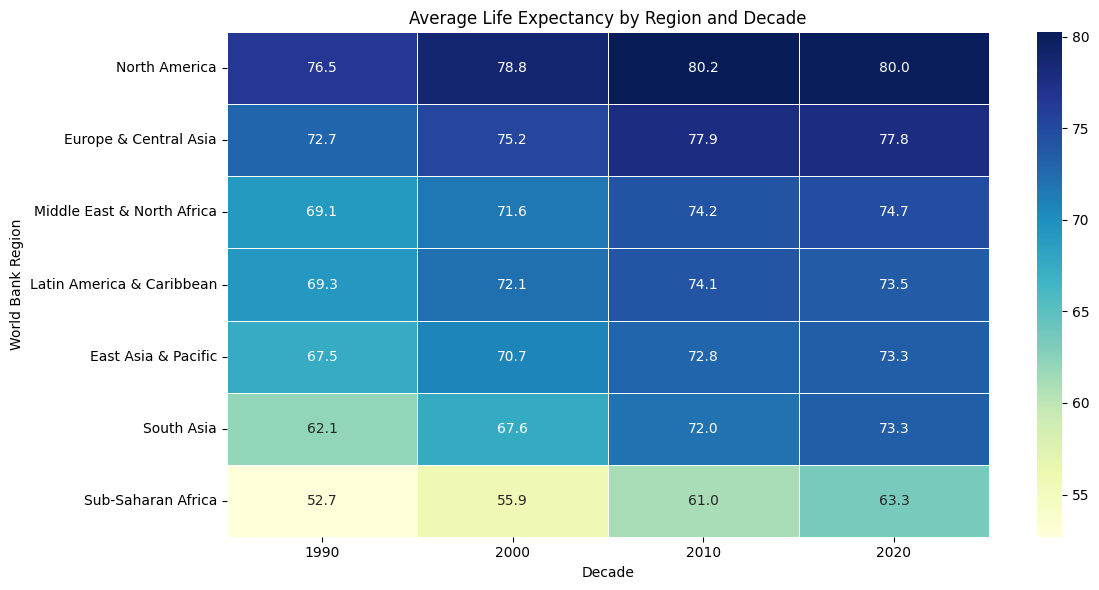

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create decade column
df["decade"] = (df["year"] // 10) * 10

# Calculate average life expectancy by region and decade
heatmap_data = df.pivot_table(
    index="region",
    columns="decade",
    values="life_expectancy",
    aggfunc="mean"
)

# Order regions by latest available decade
latest_decade = heatmap_data.columns.max()

heatmap_data = heatmap_data.sort_values(
    by=latest_decade,
    ascending=False
)

# Plot heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Life Expectancy by Region and Decade")
plt.xlabel("Decade")
plt.ylabel("World Bank Region")

plt.tight_layout()
plt.savefig("figures/p7_region_decade_heatmap.png", dpi=150)
plt.show()

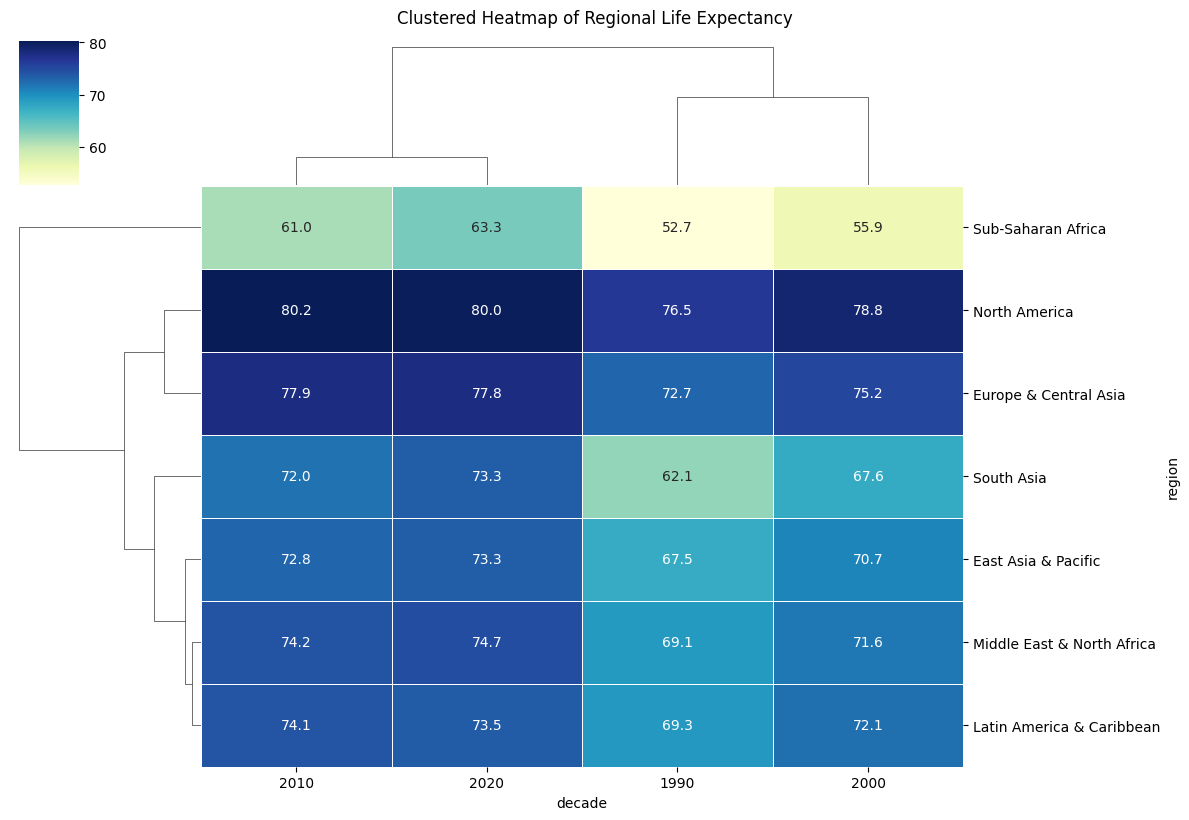

In [44]:
# Fill missing values with their respective decade averages
cluster_data = heatmap_data.fillna(
    heatmap_data.mean(axis=0)
)

cluster = sns.clustermap(
    cluster_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    figsize=(12, 8),
    row_cluster=True,
    col_cluster=True
)

cluster.fig.suptitle(
    "Clustered Heatmap of Regional Life Expectancy",
    y=1.02
)

cluster.savefig(
    "figures/p7_clustered_heatmap.png",
    dpi=150
)

plt.show()

### Region-by-Decade Heatmap

A heatmap was created to visualize average life expectancy across World Bank regions over different decades.

A sequential YlGnBu colour palette was selected because life expectancy is a continuous numerical variable. Different shades represent different values.

Regions were ordered according to their latest available decade values, making comparisons easier.

A clustered heatmap was also generated using hierarchical clustering. It groups regions and decades with similar life-expectancy patterns.

Missing values in the clustered version were filled using the corresponding decade averages solely to allow clustering.

The visualization helps identify regional differences, long-term improvements, and similarities between regions.

## Task 2: Gapminder Bubble Chart

In [45]:
import plotly.express as px

# Prepare latest available country data
bubble_df = df.dropna(
    subset=[
        "gdp_per_capita",
        "life_expectancy",
        "population",
        "region"
    ]
).copy()

latest_year = bubble_df["year"].max()

bubble_latest = bubble_df[
    bubble_df["year"] == latest_year
].copy()

# Select 8 most populated countries for direct labels
label_countries = bubble_latest.nlargest(
    8, "population"
)["country"].tolist()

bubble_latest["label"] = bubble_latest["country"].where(
    bubble_latest["country"].isin(label_countries),
    ""
)

# Create bubble chart
fig = px.scatter(
    bubble_latest,
    x="gdp_per_capita",
    y="life_expectancy",
    size="population",
    color="region",
    hover_name="country",
    text="label",
    size_max=55,
    log_x=True,
    labels={
        "gdp_per_capita": "GDP per Capita (Log Scale)",
        "life_expectancy": "Life Expectancy (Years)",
        "population": "Population",
        "region": "World Bank Region"
    },
    title=f"Gapminder Bubble Chart ({latest_year})"
)

fig.update_traces(
    textposition="top center",
    marker_sizemode="area"
)

fig.update_layout(
    width=1100,
    height=700
)

fig.show()

# Save interactive chart
fig.write_html("figures/p7_gapminder_bubble.html")

## Task 3: Treemap

In [46]:
import plotly.express as px

# Prepare latest available data
treemap_data = latest.dropna(
    subset=["region", "country", "population", "life_expectancy"]
).copy()

# Create treemap
fig = px.treemap(
    treemap_data,
    path=[
        px.Constant("World"),
        "region",
        "country"
    ],
    values="population",
    color="life_expectancy",
    color_continuous_scale="RdYlGn",
    hover_data={
        "population": ":,.0f",
        "life_expectancy": ":.1f"
    },
    title="World Population by Region and Country"
)

fig.update_layout(
    width=1100,
    height=700
)

fig.show()

# Save interactive treemap
fig.write_html("figures/p7_population_treemap.html")

### World Population Treemap

A treemap was created to visualize the distribution of world population across regions and countries.

The hierarchy begins with the world, followed by regions and individual countries. Rectangle sizes represent population, while colour represents life expectancy.

Larger rectangles indicate countries with larger populations. The colour scale makes it possible to compare life expectancy across countries.

Treemaps are useful for displaying hierarchical data and showing part-to-whole relationships. Compared with stacked bar charts, they use space efficiently and allow users to identify large contributors quickly. However, comparing similarly sized rectangles can be difficult, making precise comparisons less effective than bar charts.

## Task 4: Encoding Budget

## Task 4: Encoding Budget

### Variables and Visual Channels

| Variable | Visual Encoding | Purpose |
|---|---|---|
| GDP per capita | X-axis position (log scale) | Represents economic development |
| Life expectancy | Y-axis position | Represents health outcomes |
| Population | Bubble area | Shows country population size |
| World Bank region | Colour hue | Distinguishes geographical regions |
| Country name | Text labels and hover information | Identifies individual countries |

### Encoding Budget Analysis

The Gapminder bubble chart communicates five variables simultaneously. Position on the X and Y axes provides the most accurate comparisons, while bubble area and colour provide additional information.

The chart remains understandable because each variable uses a distinct visual channel. However, adding too many variables, colours, labels, or visual effects could increase cognitive load and make interpretation difficult.

The current design balances information density and readability. Direct labels are limited to a handful of countries to avoid clutter, while hover information provides additional details when needed.

### Part 7 Reflection

The Gapminder bubble chart communicated its message fastest to a first-time viewer because it presented economic development, life expectancy, population, and regional differences in a single visualization. The position of each bubble made relationships easy to identify, while bubble size and colour provided additional context without requiring separate charts.

# Part 8: Multivariate Visualization II (Networks, Sankey, and Geospatial Maps)

## Task 1: Network Graph

In [47]:
# Create country-by-year life expectancy table
pivot_data = df.pivot_table(
    index="country",
    columns="year",
    values="life_expectancy",
    aggfunc="mean"
)

# Calculate year-to-year changes
change_data = pivot_data.diff(axis=1)

# Calculate pairwise country correlations
correlation_matrix = change_data.T.corr(
    min_periods=15
)

# Rename index and column labels to avoid duplicate names
correlation_matrix.index.name = "source"
correlation_matrix.columns.name = "target"

# Convert correlation matrix into an edge table
edges = (
    correlation_matrix
    .stack()
    .rename("weight")
    .reset_index()
)

# Remove self-connections and keep strong positive relationships
edges = edges[
    (edges["source"] < edges["target"]) &
    (edges["weight"] >= 0.60)
].copy()

print("Number of relationships:", len(edges))

edges.head()

Number of relationships: 3971


,source,target,weight
1,Afghanistan,Albania,0.825978
7,Afghanistan,Argentina,0.756240
8,Afghanistan,Armenia,0.824222
9,Afghanistan,Aruba,0.901372
12,Afghanistan,Azerbaijan,0.798393


In [48]:
import networkx as nx

# Get the latest region for each country
country_regions = (
    df.dropna(subset=["region"])
    .sort_values("year")
    .drop_duplicates("country", keep="last")
    .set_index("country")["region"]
    .to_dict()
)

# Create graph
G = nx.Graph()

# Add countries as nodes
for country in pivot_data.index:
    if country in country_regions:
        G.add_node(
            country,
            region=country_regions[country]
        )

# Add relationships as weighted edges
for _, row in edges.iterrows():
    if row["source"] in G and row["target"] in G:
        G.add_edge(
            row["source"],
            row["target"],
            weight=row["weight"]
        )

# Remove isolated countries
G.remove_nodes_from(list(nx.isolates(G)))

print("Countries (nodes):", G.number_of_nodes())
print("Relationships (edges):", G.number_of_edges())

Countries (nodes): 178
Relationships (edges): 3971


In [49]:
# Degree centrality
degree_centrality = nx.degree_centrality(G)

# Betweenness centrality
betweenness_centrality = nx.betweenness_centrality(
    G,
    weight=None
)

# Create centrality table
centrality_df = pd.DataFrame({
    "Country": list(G.nodes()),
    "Degree Centrality": [
        degree_centrality[n] for n in G.nodes()
    ],
    "Betweenness Centrality": [
        betweenness_centrality[n] for n in G.nodes()
    ]
})

centrality_df = centrality_df.sort_values(
    "Degree Centrality",
    ascending=False
)

# Display top 10 countries
centrality_df.head(10)

,Country,Degree Centrality,Betweenness Centrality
0,Afghanistan,0.644068,0.047528
24,Bulgaria,0.564972,0.009537
107,Mozambique,0.553672,0.011738
22,Brazil,0.548023,0.015019
8,Aruba,0.542373,0.008236
35,Colombia,0.542373,0.007055
70,Guyana,0.536723,0.007781
82,Jordan,0.536723,0.005881
66,Guam,0.525424,0.030793
42,Curacao,0.525424,0.026627


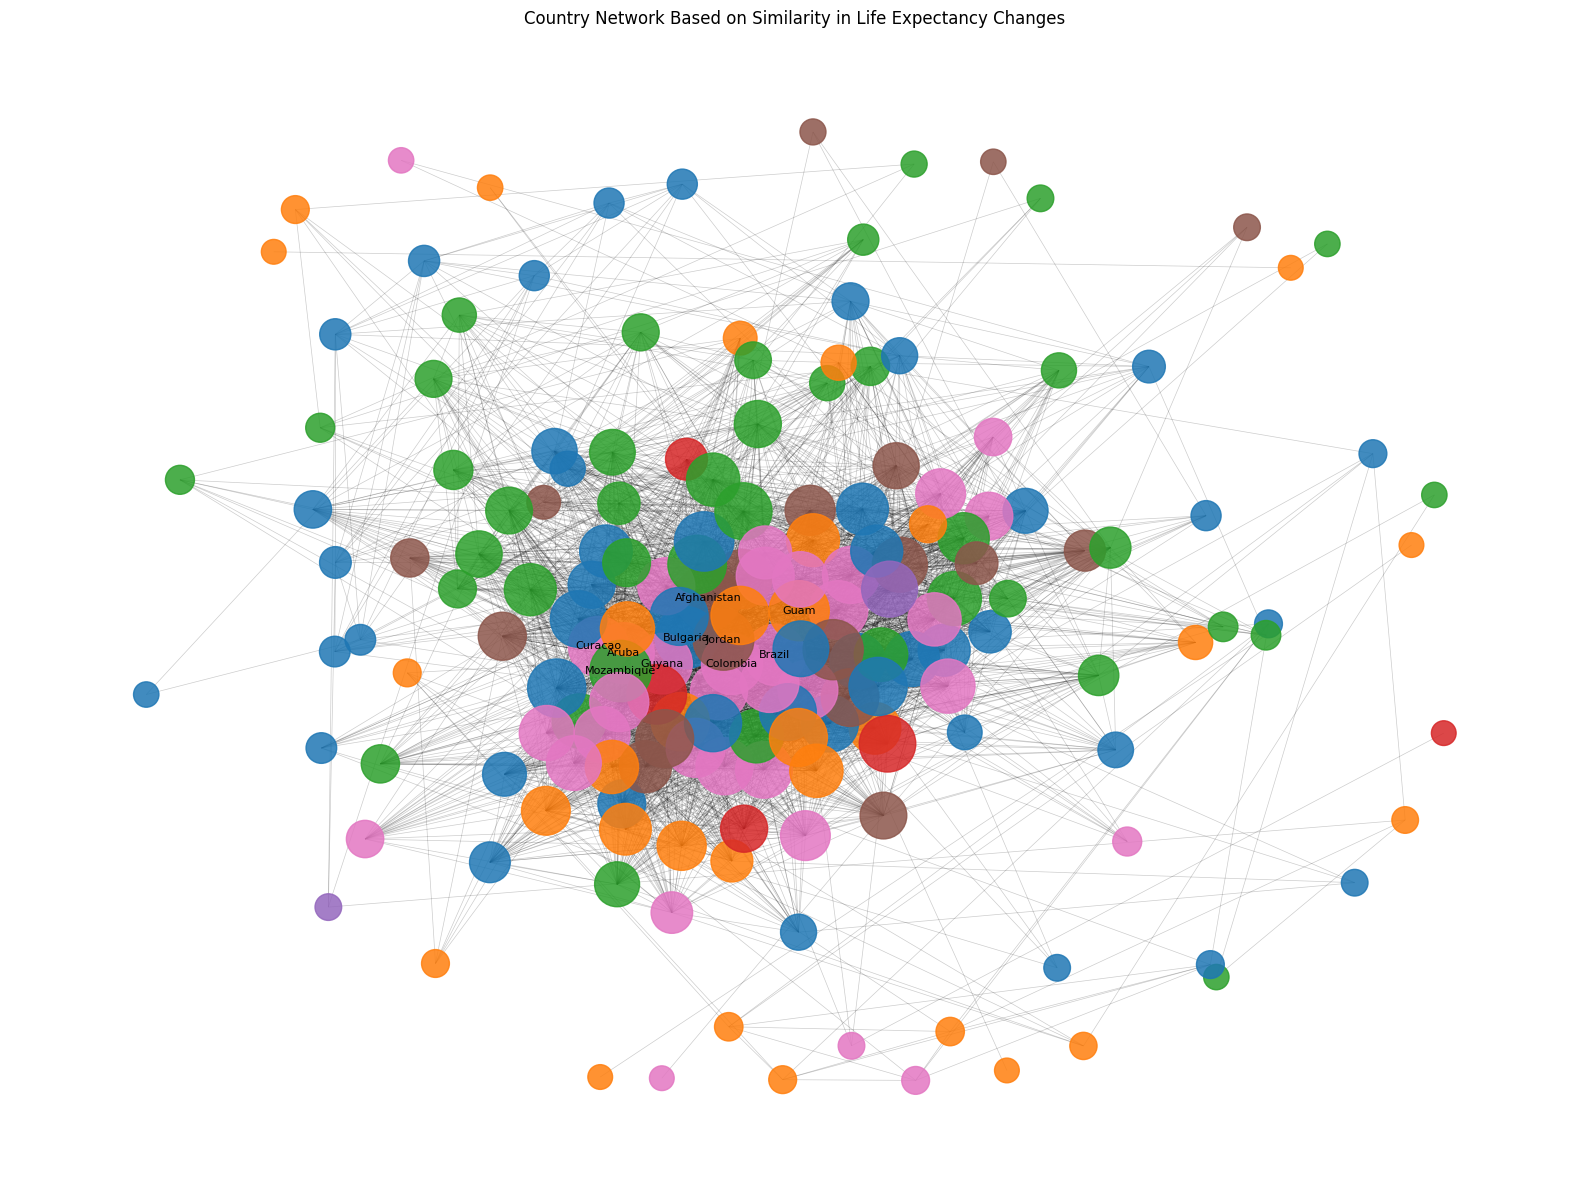

In [50]:
# Assign colours based on region
regions = list(set(
    nx.get_node_attributes(G, "region").values()
))

region_colors = {
    region: plt.cm.tab10(i % 10)
    for i, region in enumerate(regions)
}

node_colors = [
    region_colors[G.nodes[node]["region"]]
    for node in G.nodes()
]

# Node sizes based on degree centrality
node_sizes = [
    300 + degree_centrality[node] * 3000
    for node in G.nodes()
]

# Force-directed layout
pos = nx.spring_layout(
    G,
    seed=42,
    k=0.8
)

plt.figure(figsize=(16, 12))

nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.20,
    width=0.5
)

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    alpha=0.85
)

# Label the 10 most central countries
top_countries = centrality_df.head(10)["Country"].tolist()

labels = {
    node: node
    for node in top_countries
}

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=8
)

plt.title(
    "Country Network Based on Similarity in Life Expectancy Changes"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "figures/p8_network_graph.png",
    dpi=150
)

plt.show()

### Network Graph Analysis

A country relationship network was created using similarities in year-to-year life expectancy changes.

Each node represents a country, while edges represent strong positive correlations between countries. Only relationships with a correlation of at least 0.60 were retained.

Node size represents degree centrality, and node colour represents the World Bank region. A force-directed layout was used to position strongly connected countries closer together.

Degree centrality measures how many direct connections a country has relative to the possible connections. Betweenness centrality measures how frequently a country lies on shortest paths connecting other countries.

Afghanistan had the highest degree centrality (0.640449) and betweenness centrality (0.046994), making it the most connected and prominent bridging country in this network.

The hairball problem was addressed by filtering weak relationships and labelling only the ten most central countries.

**Limitation:** This is a derived similarity network, not an actual migration or trade network. Connections indicate similar life expectancy changes and should not be interpreted as evidence of direct relationships between countries.

## Task 2: Sankey Diagram

In [51]:
import plotly.graph_objects as go

# Prepare latest country data
sankey_data = latest.dropna(
    subset=["region", "country", "population", "life_expectancy"]
).copy()

# Define life expectancy categories
sankey_data["life_expectancy_group"] = pd.cut(
    sankey_data["life_expectancy"],
    bins=[0, 60, 70, 80, float("inf")],
    labels=[
        "Low (Below 60)",
        "Medium (60–70)",
        "High (70–80)",
        "Very High (Above 80)"
    ],
    right=False
)

# Aggregate population by region and life expectancy category
flow_data = sankey_data.groupby(
    ["region", "life_expectancy_group"],
    observed=True
)["population"].sum().reset_index()

flow_data.head(10)

,region,life_expectancy_group,population
0,East Asia & Pacific,Medium (60–70),1.880942e+08
1,East Asia & Pacific,High (70–80),1.920169e+09
2,East Asia & Pacific,Very High (Above 80),2.218388e+08
3,Europe & Central Asia,Medium (60–70),7.230193e+06
4,Europe & Central Asia,High (70–80),4.855375e+08
5,Europe & Central Asia,Very High (Above 80),4.314620e+08
6,Latin America & Caribbean,Medium (60–70),2.440240e+07
7,Latin America & Caribbean,High (70–80),6.174733e+08
8,Latin America & Caribbean,Very High (Above 80),1.054130e+05
9,Middle East & North Africa,Medium (60–70),2.854166e+08


In [52]:
# Get unique regions and life expectancy categories
regions = flow_data["region"].unique().tolist()

categories = [
    "Low (Below 60)",
    "Medium (60–70)",
    "High (70–80)",
    "Very High (Above 80)"
]

# Create node labels
labels = regions + categories

# Map labels to node positions
node_indices = {
    label: i for i, label in enumerate(labels)
}

# Create source, target and value lists
sources = []
targets = []
values = []

for _, row in flow_data.iterrows():
    sources.append(node_indices[row["region"]])
    targets.append(node_indices[row["life_expectancy_group"]])
    values.append(row["population"])

# Create Sankey figure
fig = go.Figure(data=[go.Sankey(
    arrangement="snap",
    node=dict(
        pad=20,
        thickness=20,
        label=labels
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values
    )
)])

fig.update_layout(
    title="Population Distribution Across Life Expectancy Groups by Region",
    width=1100,
    height=700
)

fig.show()

# Save interactive chart
fig.write_html("figures/p8_sankey_diagram.html")

## Task 3a: choropleth map

## Task 3: Geospatial Maps

### 3a. Choropleth of life expectancy
**Ask:** Which parts of the world have the highest and lowest life expectancy?
**Audience:** news readership.
**Encoding:** country shape (place) is filled with a sequential palette (Blues, light = low, dark = high). I use continuous scaling because life expectancy is a smooth numeric measure, and classes would hide differences inside a class.
**Projection:** Natural Earth, which keeps the shapes of countries recognisable and distorts area less than Mercator.

In [53]:
# Choropleth: one filled shape per country, coloured by life expectancy in the latest year
fig = px.choropleth(
    latest,
    locations="iso3",                  # country code that matches the map shapes
    color="life_expectancy",           # value that sets the fill colour
    hover_name="country",              # tooltip title
    hover_data={"iso3": False, "life_expectancy": ":.1f"},
    color_continuous_scale="Blues",    # sequential palette: low = light, high = dark
    labels={"life_expectancy": "Life expectancy (years)"},
    title=f"Life expectancy is lowest in Sub-Saharan Africa and highest in Europe and East Asia ({LATEST})",
)

fig.update_geos(projection_type="natural earth", showframe=False)
fig.update_layout(coloraxis_colorbar=dict(title="Years"))
fig.add_annotation(text=SOURCE, xref="paper", yref="paper", x=0, y=-0.05, showarrow=False)

fig.write_html("figures/p8_choropleth.html")
fig.show()

## Task 3b: proportional symbol map

### 3b. Proportional symbol map of population
**Ask:** Where do most people live?
**Audience:** news readership.
**Encoding:** one circle per country at its location. Circle **area** is proportional to population, and colour is the World Bank region. Area is used instead of radius, because scaling by radius would exaggerate big countries.

In [54]:
# Proportional symbol map: circle area = population
fig = px.scatter_geo(
    latest,
    locations="iso3",                  # place each circle on the country
    size="population",                 # circle size
    color="region",                    # colour by region
    hover_name="country",
    hover_data={"iso3": False, "population": ":,.0f"},
    size_max=50,                       # biggest circle in pixels
    projection="natural earth",
    labels={"population": "Population", "region": "Region"},
    title=f"Most of the world's people live in a few large Asian countries ({LATEST})",
)

# Make sure size is mapped to area, not radius
fig.update_traces(marker=dict(sizemode="area"))
fig.update_geos(showframe=False)
fig.add_annotation(text=SOURCE + ". Circle area = population.", xref="paper", yref="paper", x=0, y=-0.05, showarrow=False)

fig.write_html("figures/p8_proportional_symbol_map.html")
fig.show()

### Map pitfalls and projection
**Choropleth pitfall:** large countries with few people, such as Russia, Canada and Australia, take up most of the visual space and draw the eye, while small, dense countries are hard to see. The proportional symbol map fixes this because circle size shows population instead of land area.

**Projection:** I used the Natural Earth projection. Mercator inflates areas near the poles, so Greenland and Russia look much bigger than they are. Natural Earth is a compromise that keeps country shapes recognisable and distorts area less.

**Limitation:** circles on small countries can overlap, and circle area is harder to read exactly than position, so exact values are in the tooltips.

### Task 4: Map accessibility
**Legend:** the choropleth colour bar is labelled in years, and the symbol map legend lists regions and states that circle area equals population.
**Colour vision check:** I test the Blues palette used in the choropleth under three colour vision deficiencies and in grayscale.
**Text summary:** a written description of the main geographic pattern, for readers who cannot see the map.

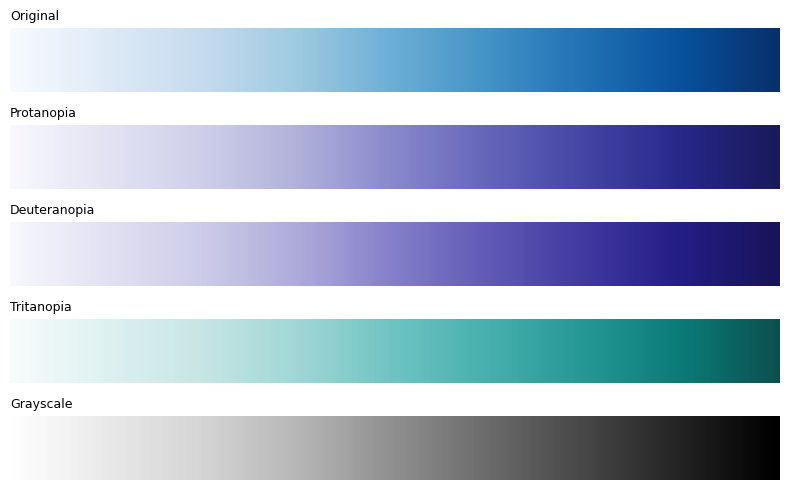

In [55]:
# Build a strip of 256 colours from the Blues palette (the one used in the choropleth)
strip = plt.cm.Blues(np.linspace(0, 1, 256))[:, :3]
strip = (np.tile(strip[np.newaxis, :, :], (40, 1, 1)) * 255).astype(np.uint8)

fig, axes = plt.subplots(5, 1, figsize=(8, 5))
views = {
    "Original": strip,
    "Protanopia": simulate_cvd(strip, "Protanopia"),
    "Deuteranopia": simulate_cvd(strip, "Deuteranopia"),
    "Tritanopia": simulate_cvd(strip, "Tritanopia"),
    "Grayscale": np.mean(strip, axis=2).astype(np.uint8),
}

for ax, (name, img) in zip(axes, views.items()):
    ax.imshow(img, cmap="gray" if name == "Grayscale" else None, aspect="auto")
    ax.set_title(name, fontsize=9, loc="left")
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/p8_map_palette_audit.png", dpi=150)
plt.show()

In [56]:
# Facts to write the summary from
print("Highest 5:")
print(latest.nlargest(5, "life_expectancy")[["country", "life_expectancy"]].round(1).to_string(index=False))
print("\nLowest 5:")
print(latest.nsmallest(5, "life_expectancy")[["country", "life_expectancy"]].round(1).to_string(index=False))
print("\nRegion averages:")
print(latest.groupby("region")["life_expectancy"].mean().round(1).sort_values(ascending=False))

Highest 5:
      country  life_expectancy
       Monaco             85.7
   San Marino             85.7
Liechtenstein             84.1
      Andorra             84.0
        Japan             84.0

Lowest 5:
           country  life_expectancy
Somalia, Fed. Rep.             53.9
           Nigeria             54.1
              Chad             54.5
           Lesotho             56.8
              Mali             60.0

Region averages:
region
North America                 80.2
Europe & Central Asia         78.4
Middle East & North Africa    75.9
South Asia                    74.5
Latin America & Caribbean     74.5
East Asia & Pacific           73.6
Sub-Saharan Africa            64.1
Name: life_expectancy, dtype: float64


**Text summary of the map pattern (for readers who cannot see the map):**
Life expectancy in 2022 is highest in North America (about 80 years on average) and Europe and Central Asia (about 78). The top countries are Monaco and San Marino (85.7), Liechtenstein (84.1), and Andorra and Japan (84.0). The Middle East and North Africa (75.9), South Asia and Latin America and the Caribbean (74.5), and East Asia and Pacific (73.6) sit in the middle. Sub-Saharan Africa is clearly lowest at about 64 years on average, with Somalia, Nigeria, Chad and Lesotho between 54 and 57 years. The pattern is mostly regional: the gap between the highest and lowest regions is about 16 years.

# Part 9: Final Visual Story

**Audience:** a ministry of health planning where to focus health spending.
**Central message:** Where a person is born still decides how long they live. Income explains much of the gap, but not all of it.

In [57]:
print(heatmap_data.max() - heatmap_data.min())

decade
1990    23.845943
2000    22.914810
2010    19.217705
2020    16.661495
dtype: float64


## Figure 1: Where is life expectancy lowest?
Life expectancy is lowest in Sub-Saharan Africa and highest in Europe, North America and parts of East Asia.
**Takeaway:** The lowest-expectancy countries cluster in one region, so this is a regional problem, not a scatter of individual cases.

In [58]:
import plotly.graph_objects as go

# Base map: same choropleth as Part 8, Blues palette (stays readable in colour blindness and grayscale)
fig = px.choropleth(
    latest,
    locations="iso3",
    color="life_expectancy",
    hover_name="country",
    hover_data={"iso3": False, "life_expectancy": ":.1f"},
    color_continuous_scale="Blues",
    labels={"life_expectancy": "Years"},
    title=f"Life expectancy is lowest in Sub-Saharan Africa ({LATEST})",
)

# Callout placed directly on the map (longitude, latitude of central Africa)
fig.add_trace(go.Scattergeo(
    lon=[20], lat=[2],
    text=["Sub-Saharan Africa:<br>about 64 years on average"],
    mode="markers+text",
    textposition="bottom right",
    marker=dict(size=10, color="red", symbol="circle-open", line=dict(width=3)),
    showlegend=False,
    hoverinfo="skip",
))

fig.update_geos(projection_type="natural earth", showframe=False)
fig.add_annotation(text=SOURCE, xref="paper", yref="paper", x=0, y=-0.05, showarrow=False)

fig.write_html("figures/p9_fig1_choropleth.html")
fig.show()

## Figure 2: How big is the gap?
The highest region (North America) lives about 16 years longer than the lowest (Sub-Saharan Africa).
**Takeaway:** The gap between regions is large: 16 years of life.

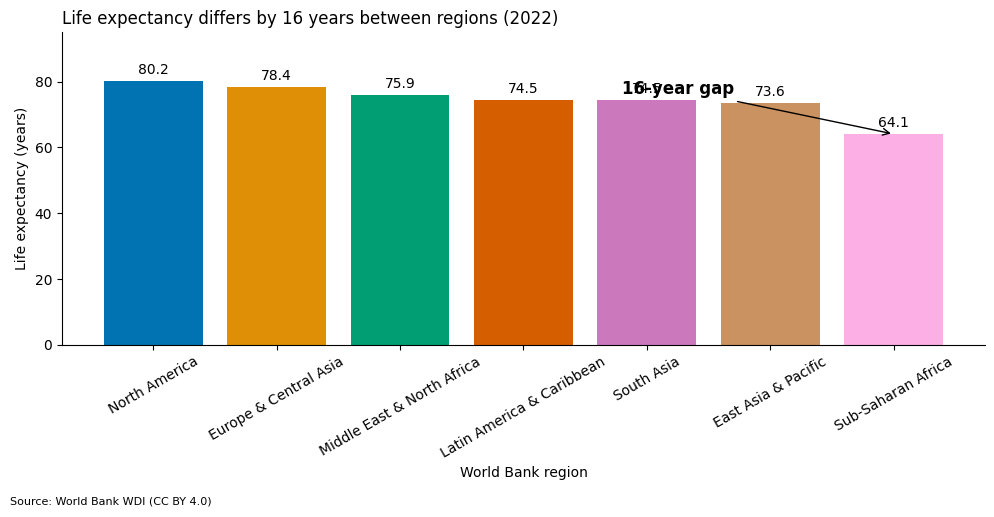

In [59]:
import seaborn as sns

# Average life expectancy per region, sorted high to low (recomputed so it excludes the removed country)
region_avg = (latest.groupby("region")["life_expectancy"].mean()
              .sort_values(ascending=False).reset_index())

# Colourblind-safe palette, one colour per region
colors = sns.color_palette("colorblind", len(region_avg))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(region_avg["region"], region_avg["life_expectancy"], color=colors)

# Direct labels so the chart does not depend on colour alone
ax.bar_label(bars, fmt="%.1f", padding=3)

# Callout: the gap between highest and lowest
top = region_avg["life_expectancy"].iloc[0]
bottom = region_avg["life_expectancy"].iloc[-1]
ax.annotate(f"{top - bottom:.0f}-year gap",
            xy=(len(region_avg) - 1, bottom), xytext=(len(region_avg) - 3.2, top - 4),
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=12, fontweight="bold")

ax.set_ylim(0, 95)                      # axis starts at zero, so bar lengths are honest
ax.set_ylabel("Life expectancy (years)")
ax.set_xlabel("World Bank region")
ax.set_title(f"Life expectancy differs by {top - bottom:.0f} years between regions ({LATEST})", loc="left")
ax.tick_params(axis="x", rotation=30)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.text(0.01, -0.02, SOURCE, fontsize=8)

plt.tight_layout()
plt.savefig("figures/p9_fig2_region_bars.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 3: Is the gap closing?
The gap between the highest and lowest region narrowed from about 24 years in 1990 to about 17 years in 2020, but it has not closed.
**Takeaway:** Every region improved, and the lowest region improved most, yet a 17-year gap remains.

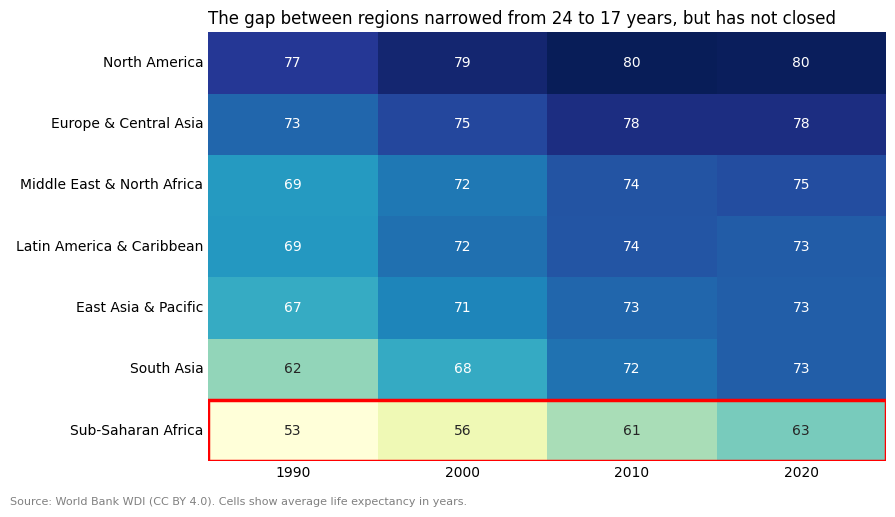

In [60]:
from matplotlib.patches import Rectangle

df["decade"] = (df["year"] // 10) * 10
heat = df.pivot_table(index="region", columns="decade",
                      values="life_expectancy", aggfunc="mean")
heat = heat.sort_values(by=heat.columns.max(), ascending=False)

gap_first = heat.iloc[:, 0].max() - heat.iloc[:, 0].min()
gap_last = heat.iloc[:, -1].max() - heat.iloc[:, -1].min()

fig, ax = plt.subplots(figsize=(9, 5))

# Numbers give exact values, so the colour bar and cell borders are removed
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlGnBu",
            linewidths=0, cbar=False, ax=ax)

# One callout: outline the lowest region
row = list(heat.index).index("Sub-Saharan Africa")
ax.add_patch(Rectangle((0, row), heat.shape[1], 1, fill=False, edgecolor="red", lw=2.5))

# The gap goes in the title, so no extra text is needed
ax.set_title(f"The gap between regions narrowed from {gap_first:.0f} to {gap_last:.0f} years, but has not closed",
             loc="left", fontsize=12)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
fig.text(0.01, -0.02, SOURCE + ". Cells show average life expectancy in years.", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("figures/p9_fig3_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Figure 4: Does income explain the gap?
Richer countries live longer, but countries with similar income still differ by many years.
**Takeaway:** Income explains much of the pattern, but not all of it, so policy choices matter too.

In [61]:
# Mark countries in the income band (US$4,000 to 8,000)
latest = latest.copy()
latest["group"] = np.where(latest["gdp_per_capita"].between(4000, 8000), "Income band", "Other")
band = latest[latest["group"] == "Income band"]
spread = band["life_expectancy"].max() - band["life_expectancy"].min()
print(len(band), "countries in the band, spread:", round(spread, 1), "years")

fig = px.scatter(
    latest, x="gdp_per_capita", y="life_expectancy",
    color="group", color_discrete_map={"Income band": "#08519c", "Other": "lightgray"},
    hover_name="country", log_x=True,
    labels={"gdp_per_capita": "GDP per capita (US$, log scale)", "life_expectancy": "Life expectancy (years)"},
    title=f"At similar income, life expectancy still differs by {spread:.0f} years ({LATEST})",
)
fig.update_traces(marker=dict(size=12))
fig.add_vrect(x0=4000, x1=8000, fillcolor="lightblue", opacity=0.2, line_width=0)  # shaded income band
fig.update_layout(template="plotly_white", showlegend=False, height=700, font=dict(size=14))
fig.write_html("figures/p9_fig4_income_band.html")
fig.show()

40 countries in the band, spread: 15.4 years


## Figure 5: Is income the whole story?
Within the same region, countries differ widely in life expectancy.
**Takeaway:** Region and income matter, but countries in the same region still differ by many years, so national policy matters too.

In [62]:
# Range of life expectancy inside each region, to find the most uneven one
ranges = latest.groupby("region")["life_expectancy"].agg(lambda s: s.max() - s.min()).sort_values()
widest, widest_range = ranges.index[-1], ranges.iloc[-1]
print(ranges.round(1))

fig = px.box(
    latest, y="region", x="life_expectancy",
    points="all",                       # every country shown as a dot on top of the box
    hover_name="country",
    category_orders={"region": ranges.index.tolist()},
    labels={"life_expectancy": "Life expectancy (years)", "region": ""},
    title=f"Countries in the same region differ widely; {widest} spans {widest_range:.0f} years ({LATEST})",
)
fig.update_traces(marker=dict(size=6, color="#08519c"), line=dict(color="gray"), fillcolor="rgba(0,0,0,0)")
fig.update_layout(template="plotly_white", height=650, font=dict(size=14))
fig.write_html("figures/p9_fig5_region_spread.html")
fig.show()

region
North America                  4.6
South Asia                    10.7
Europe & Central Asia         15.8
Latin America & Caribbean     16.4
Middle East & North Africa    17.2
Sub-Saharan Africa            22.0
East Asia & Pacific           22.1
Name: life_expectancy, dtype: float64


## Methods note
**Data source:** World Bank World Development Indicators (WDI), CC BY 4.0. Indicators used: life expectancy at birth, GDP per capita (current US$), CO2 emissions per capita, internet users (% of population) and total population, for 1990 to 2022. Region comes from the WDI country file.

**Cleaning decisions:**
- Aggregates such as "World" and "Low income" were removed, because they have no region and would double count.
- Rows missing life expectancy, GDP or population were dropped (350 rows). Missing CO2 and internet values were left as missing, not filled with zero.
- Central African Republic was removed because its life expectancy swings by more than 20 years between years (for example 31.5 in 2019, 50.6 in 2020, 18.8 in 2022), which is not plausible and is likely a source error.
- 2022 was used as the latest year because it still covers at least 179 countries in every column.

**Known limitations:**
- Regional averages are simple averages of countries, not weighted by population.
- The network and Sankey in Part 8 use a derived relationship table (similarity in life expectancy changes, and population grouped by life expectancy band). They are not real migration or trade flows.
- Correlations and charts show association, not causation.
- A few small countries (for example Monaco and San Marino) have very small populations, so their values are less stable.

In [63]:
from IPython.display import Markdown

Markdown(f"""
# Born in the wrong place, living {top - bottom:.0f} years less
*A visual story for a ministry of health planning where to focus health spending.*

**Does where a person is born still decide how long they live?**

**1. Where.** Life expectancy is lowest in Sub-Saharan Africa and highest in North America, Europe and parts of East Asia (Figure 1). The low-expectancy countries sit together in one region, so this is a regional problem, not a scatter of individual cases.

**2. How big.** The highest region lives {top - bottom:.0f} years longer than the lowest (Figure 2). That is a gap of {top - bottom:.0f} years of life.

**3. Is it closing?** Partly. The gap between the highest and lowest region narrowed from {gap_first:.0f} years in 1990 to {gap_last:.0f} years in 2020, and every region improved (Figure 3). The lowest region improved most, but the gap has not closed.

**4. Is it income?** Richer countries live longer, but income is not the whole story. Countries with similar income (US$4,000 to 8,000 per person) still differ by {spread:.0f} years of life (Figure 4).

**5. Is it the region?** Not entirely. Even inside one region, countries differ widely: {widest} spans {widest_range:.0f} years (Figure 5).

**Takeaway for the ministry:** Income and region explain much of the gap, but not all of it. Countries with the same resources reach very different outcomes, so national health policy and spending choices matter.
""")


# Born in the wrong place, living 16 years less
*A visual story for a ministry of health planning where to focus health spending.*

**Does where a person is born still decide how long they live?**

**1. Where.** Life expectancy is lowest in Sub-Saharan Africa and highest in North America, Europe and parts of East Asia (Figure 1). The low-expectancy countries sit together in one region, so this is a regional problem, not a scatter of individual cases.

**2. How big.** The highest region lives 16 years longer than the lowest (Figure 2). That is a gap of 16 years of life.

**3. Is it closing?** Partly. The gap between the highest and lowest region narrowed from 24 years in 1990 to 17 years in 2020, and every region improved (Figure 3). The lowest region improved most, but the gap has not closed.

**4. Is it income?** Richer countries live longer, but income is not the whole story. Countries with similar income (US$4,000 to 8,000 per person) still differ by 15 years of life (Figure 4).

**5. Is it the region?** Not entirely. Even inside one region, countries differ widely: East Asia & Pacific spans 22 years (Figure 5).

**Takeaway for the ministry:** Income and region explain much of the gap, but not all of it. Countries with the same resources reach very different outcomes, so national health policy and spending choices matter.


## Reflection

Before this project I thought most of the work in data visualization was choosing the chart. The workflow taught me the opposite. Preparing the data took longest: the World Bank file had one column per year and mixed real countries with groups like "World", so I had to reshape and filter it before I could draw anything. That step also taught me to look at the data before trusting it. Central African Republic showed a life expectancy of 18.8 in 2022, and when I checked other years the values jumped between 31 and 52, which is not believable. I removed it and wrote the decision in my cleaning log. Without that check, my lowest region and my perception experiment would have been distorted by one bad number.

The principle that changed my habits most was the data-ink ratio. My first heatmap had a colour bar, grid lines, a coloured callout, a title and axis labels that all repeated the same information. When I removed everything that did not carry information and put the finding in the title, the chart became much easier to read. I now ask of every element: what does the reader lose if I delete this?

I also learned that honest charts need as much care as attractive ones. When I calculated the lie factor, my first axis choice was wrong, and I had to fix the baseline before the number made sense. It showed me how easily a truncated axis can be committed by accident, so I now check where every bar axis starts.

Finally, I learned that interactivity should serve the question. Hover tooltips and legend filtering helped me explore the data, but in the visual story I used annotated charts with one clear callout each, so the reader does not need a mouse to get the point.

With more time, I would replace my derived network and Sankey data with the real UN migrant stock table, weight regional averages by population, test the charts with more readers, and deploy the dashboard. I would also check every country for unreliable series instead of only the one I happened to notice.